# Notebook 05 — Classificação supervisionada: o modelo acerta janelas que nunca viu?

**O que muda em relação ao Notebook 04:** lá, o K-Means **não via os rótulos**, e todas as janelas foram usadas para tudo. Aqui o modelo **aprende com os rótulos**. Então passa a existir o risco de ele **decorar** em vez de aprender: acertar as janelas do treino e errar as novas. **Todo o cuidado deste notebook é para o teste ser honesto.**

**O que esperar dos números:** com a fita, que separa quase perfeitamente, os acertos devem ficar perto de 100% de novo. **O valor deste notebook é o método**: uma divisão treino/teste sem vazamento, pronta para os dados novos, em que as falhas serão mais sutis.

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1–2 | Configuração, bases, 109 features | A mesma tabela dos notebooks anteriores |
| 3 | Medir até onde janelas vizinhas se parecem | Escolher o tamanho do bloco e da guarda **pelos dados** |
| 4 | Cortar em blocos e separar o teste trancado | Um teste que não "cola" do treino (com figura) |
| 5 | Validação cruzada por blocos | Como escolher modelos sem tocar no teste trancado (com figura) |
| 6 | Pipeline log → scaler → modelo | O scaler ajustado **só no treino** |
| 7 | Métricas e modelos | Acurácia balanceada; modelos de referência e classificadores |
| 8 | Tarefa A: velocidade | Qual a velocidade de qualquer janela, normal ou com falha |
| 9 | Tarefa B: normal × anomalia | Detecção supervisionada |
| 10 | Tarefa C: 6 classes | Classificador único × arquitetura em duas etapas |
| 11 | Testes anti-ilusão | O resultado é real ou artefato? |
| 12 | Regra de escolha e **abertura do teste trancado** | O número final, aberto uma vez só |
| Resumo | Decisões | O que levar para o 05b e para o modelo final |

**O Notebook 05b** fará o teste mais exigente: um detector que **só conhece o ventilador saudável** e acusa o que foge dele, usando a mesma divisão em blocos deste notebook.

## Ressalvas que valem para todo o notebook

* **Uma falha só (fita).** A tarefa "qual é o tipo de falha" (a segunda etapa da arquitetura) não pode ser testada ainda. O código já está pronto para quando houver mais falhas.
* **Uma gravação por classe.** Treino e teste vêm **da mesma gravação**, só que de trechos diferentes. Isso mede se o modelo generaliza **dentro da sessão**. Generalizar para **outra sessão** (outro dia, sensor reposicionado) só a nova coleta mostra.
* **O teste trancado só pode ser aberto uma vez**, no Passo 12, depois de todas as escolhas. Se você mudar algo depois de vê-lo, ele deixa de ser um teste honesto.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte. Precisa de `scikit-learn`.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. Os blocos "DIVISÃO", "VALIDAÇÃO" e "ESCOLHA" são explicados nos Passos 3, 4, 5 e 12.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.stats import kurtosis
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos notebooks anteriores)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\BASES_ROTULADAS")

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA (NORMAL) E QUEM É ANOMALIA
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta
NOME_NORMAL = "normal"
NOME_ANOMALIA = "anomalia"

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6
COLUNAS_SEM_LOG = ["kurt_x", "kurt_y", "kurt_z"]   # a curtose pode ser negativa: não aceita log

# ----------------------------------------------------------------------
# DIVISÃO EM BLOCOS E TESTE TRANCADO (Passos 3 e 4)
# ----------------------------------------------------------------------
BLOCO_JANELAS = 12                # 12 janelas de 5 s = blocos de 60 s
GUARDA_JANELAS = 2                # 2 janelas (10 s) descartadas de cada lado da fronteira treino/teste
BLOCOS_TRANCADOS_POR_BASE = 2     # blocos de cada gravação sorteados para o teste trancado
LAG_MAXIMO = 24                   # até onde medir a autocorrelação no Passo 3 (24 janelas = 2 min)

# ----------------------------------------------------------------------
# VALIDAÇÃO CRUZADA (Passo 5)
# ----------------------------------------------------------------------
N_FOLDS = 5
SEMENTE = 42                      # fixa todos os sorteios: o resultado é sempre o mesmo

# ----------------------------------------------------------------------
# ESCOLHA E TESTES (Passos 11 e 12)
# ----------------------------------------------------------------------
CONJUNTO_PRINCIPAL = "todas"      # conjunto de features mostrado nas matrizes
EMPATE_PP = 0.5                   # diferença (pontos percentuais) abaixo da qual dois modelos empatam
N_EMBARALHAMENTOS = 20            # repetições do teste de rótulos embaralhados
FRACAO_INICIO_CRONOLOGICO = 0.7   # na divisão cronológica, treina nos primeiros 70% de cada gravação

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_TIPO = {"tempo": "tab:green", "FFT": "tab:purple", "rotação": "tab:orange"}

## Passo 2 — Carregar as bases e calcular as 109 features

**O que buscamos:** a mesma tabela dos notebooks anteriores. **O código desta parte é copiado do Notebook 02 sem alterações.**

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

Referência: ['ventilador_normal']
Comparadas: ['fita_1g']


bases  duracao_s
condicao          velocidade                  
fita_1g           1               1      560.0
                  2               1      550.0
                  3               1      590.0
ventilador_normal 1               1      600.0
                  2               1      570.0
                  3               1      510.0

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

In [7]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
features = features.sort_values(["base", "janela"]).reset_index(drop=True)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO
CONJUNTOS = {"tempo": COLUNAS_TEMPO, "FFT": COLUNAS_FFT, "rotação": COLUNAS_ROTACAO, "todas": COLUNAS_TODAS}

eh_normal = features["condicao"].isin(CONDICOES_REFERENCIA)
features["rotulo_condicao"] = np.where(eh_normal, NOME_NORMAL, features["condicao"])
features["rotulo_binario"] = np.where(eh_normal, NOME_NORMAL, NOME_ANOMALIA)
features["rotulo_velocidade"] = "V" + features["velocidade"].astype(str)
features["rotulo_classe"] = features["rotulo_condicao"] + " " + features["rotulo_velocidade"]

ORDEM_CONDICOES = [NOME_NORMAL] + list(condicoes_comparadas)
ORDEM_VELOCIDADES = [f"V{v}" for v in velocidades]
ORDEM_CLASSES = [f"{c} {v}" for v in ORDEM_VELOCIDADES for c in ORDEM_CONDICOES if f"{c} {v}" in set(features["rotulo_classe"])]

print(f"{len(COLUNAS_TODAS)} features; {len(features)} janelas")
display(features.groupby(["rotulo_velocidade", "rotulo_condicao"]).size().unstack().reindex(columns=ORDEM_CONDICOES))

109 features; 676 janelas


rotulo_condicao,normal,fita_1g
rotulo_velocidade,,
V1,120,112
V2,114,110
V3,102,118


## Passo 3 — Até onde as janelas vizinhas se parecem?

**O problema (vazamento por vizinhança):** se a janela 40 fica no treino e a janela 41 no teste, o modelo pode acertar a 41 só porque ela é quase igual à 40, que ele já viu. Ele "cola da vizinha". O acerto sai otimista e não vale para dados realmente novos.

**A solução:** em vez de sortear janelas soltas, sorteamos **blocos de janelas seguidas** e colocamos cada bloco inteiro no treino **ou** no teste. Entre um bloco de treino e um de teste deixamos uma **guarda**: algumas janelas descartadas, para que as vizinhas imediatas nunca fiquem em lados opostos.

**Como escolher o tamanho do bloco e da guarda:** medindo nos dados até onde a semelhança vai. Para cada gravação, calculamos a **autocorrelação** das features para cada distância (lag) entre janelas: lag 1 = vizinha, lag 2 = duas janelas depois etc. Resumimos as 109 features pela mediana.

Mostramos a mesma informação de três jeitos, do mais resumido ao mais detalhado:

1. **Mapa de cores (3.1):** todas as gravações e distâncias numa figura só.
2. **Barras por gravação (3.2):** o padrão de cada gravação separado.
3. **Matriz de semelhança (3.3):** cada janela contra cada outra, sem resumir por distância.

In [8]:
def calcular_autocorrelacao_com_sinal(features, colunas, lag_maximo=LAG_MAXIMO):
    """Por gravação: mediana, entre as features, da autocorrelação (com sinal) para cada distância de 1 a lag_maximo."""
    curvas = {}
    for base, grupo in features.groupby("base"):
        grupo = grupo.sort_values("janela")
        curvas[base] = [np.nanmedian([grupo[c].autocorr(lag) for c in colunas]) for lag in range(1, lag_maximo + 1)]
    return pd.DataFrame(curvas, index=pd.Index(range(1, lag_maximo + 1), name="lag (janelas)"))


def ordenar_bases(nomes):
    """Ordena as gravações por velocidade e depois por nome."""
    return sorted(nomes, key=lambda b: (b.split("_vel_")[1], b))

### 3.1 — Mapa de cores: todas as gravações e distâncias numa só figura

**Como ler:** cada linha é uma gravação e cada coluna uma distância entre janelas (em janelas e em segundos). A cor é a semelhança:

* **vermelho:** janelas a essa distância são **parecidas**;
* **azul:** são **opostas** (quando uma está alta, a outra está baixa, ou seja, **alternância**);
* **branco:** sem relação.

Os números aparecem só nas células mais fortes (|valor| ≥ 0,3). A linha preta contínua marca o fim da **guarda** e a tracejada o fim de um **bloco**. **O que procurar:** colunas inteiras vermelhas (uma distância em que todas as gravações se repetem) e células fortes à esquerda da linha contínua (a vizinhança que a guarda precisa cobrir).

In [9]:
def plotar_mapa_autocorrelacao(curvas):
    """Mapa: linhas = gravações, colunas = distância entre janelas, cor = semelhança (com sinal)."""
    bases = ordenar_bases(curvas.columns)
    grade = curvas[bases].T
    fig, ax = plt.subplots(figsize=(15, 0.6 * len(bases) + 2.2))
    imagem = ax.imshow(grade.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    for i in range(grade.shape[0]):
        for j in range(grade.shape[1]):
            valor = grade.iat[i, j]
            if abs(valor) >= 0.3:
                ax.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(valor) > 0.45 else "black")
    ax.set_xticks(range(grade.shape[1]))
    ax.set_xticklabels([f"{lag}\n{lag * JANELA_S}s" for lag in grade.columns], fontsize=7)
    ax.set_yticks(range(len(bases)))
    ax.set_yticklabels(bases, fontsize=8)
    ax.axvline(GUARDA_JANELAS - 0.5, color="black", linewidth=2.5, label=f"fim da guarda ({GUARDA_JANELAS} janelas)")
    ax.axvline(BLOCO_JANELAS - 0.5, color="black", linewidth=2, linestyle="--", label=f"fim do bloco ({BLOCO_JANELAS} janelas)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=9)
    ax.grid(False)
    ax.set_xlabel("distância entre as janelas (em janelas / em segundos)")
    fig.colorbar(imagem, ax=ax, label="semelhança (vermelho = parecidas, azul = opostas)", shrink=0.8)
    ax.set_title("Semelhança entre janelas a cada distância", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

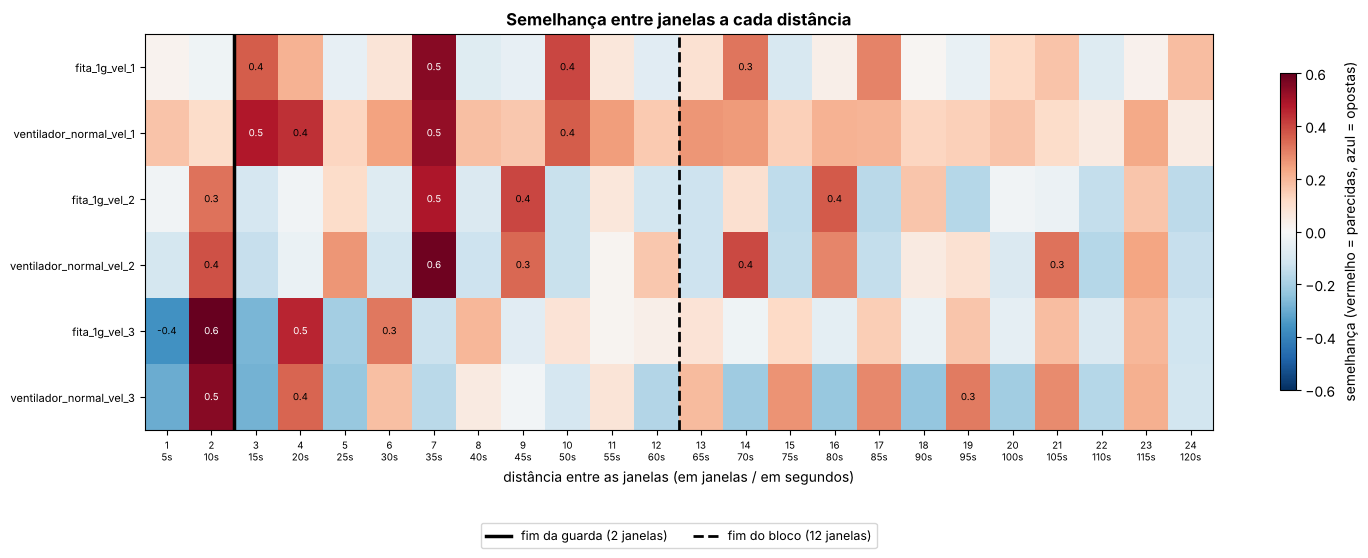

In [10]:
curvas_autocorrelacao = calcular_autocorrelacao_com_sinal(features, COLUNAS_TODAS)
plotar_mapa_autocorrelacao(curvas_autocorrelacao)

### 3.2 — Barras por gravação: o padrão de cada uma

**Como ler:** um painel por gravação, com uma barra para cada distância. **Barra vermelha para cima** = parecidas; **barra azul para baixo** = opostas. A faixa laranja é a **guarda** (essas janelas vizinhas são descartadas) e a linha tracejada é o fim de um **bloco**.

**Os três padrões que dá para reconhecer:**

* **Barras vermelhas que vão diminuindo devagar, sem azul:** deriva lenta (a gravação muda aos poucos do começo ao fim).
* **Vermelho e azul alternando (uma barra sim, outra não):** alternância forte/fraca, o ciclo da oscilação cortado pelas janelas de 5 s.
* **Picos vermelhos isolados em certas distâncias** (por exemplo, a cada 7 janelas): o ciclo voltando à mesma fase.

In [11]:
def plotar_barras_por_base(curvas):
    """Um painel por gravação: barras da semelhança a cada distância, com a guarda e o fim do bloco."""
    bases = ordenar_bases(curvas.columns)
    linhas = int(np.ceil(len(bases) / 2))
    fig, axs = plt.subplots(linhas, 2, figsize=(16, 2.4 * linhas + 1.2), sharex=True, sharey=True, squeeze=False)
    for ax, base in zip(axs.T.ravel(), bases):
        valores = curvas[base]
        ax.bar(valores.index, valores.values, color=np.where(valores.values >= 0, "tab:red", "tab:blue"), width=0.8)
        ax.axvspan(0.5, GUARDA_JANELAS + 0.5, color="orange", alpha=0.25)
        ax.axvline(BLOCO_JANELAS + 0.5, color="black", linestyle="--", linewidth=1)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(base, fontsize=10, fontweight="bold", loc="left")
        ax.set_ylim(-0.7, 0.7)
    for ax in axs[-1]:
        ax.set_xlabel(f"distância (janelas de {JANELA_S} s)")
    for ax in axs[:, 0]:
        ax.set_ylabel("semelhança")
    fig.legend(handles=[Patch(color="orange", alpha=0.4, label="guarda (descartada)"), Patch(color="tab:red", label="parecidas"),
                        Patch(color="tab:blue", label="opostas (alternância)")], loc="lower center", fontsize=9, ncol=3)
    fig.suptitle("Semelhança entre janelas a cada distância, por gravação", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    plt.show()

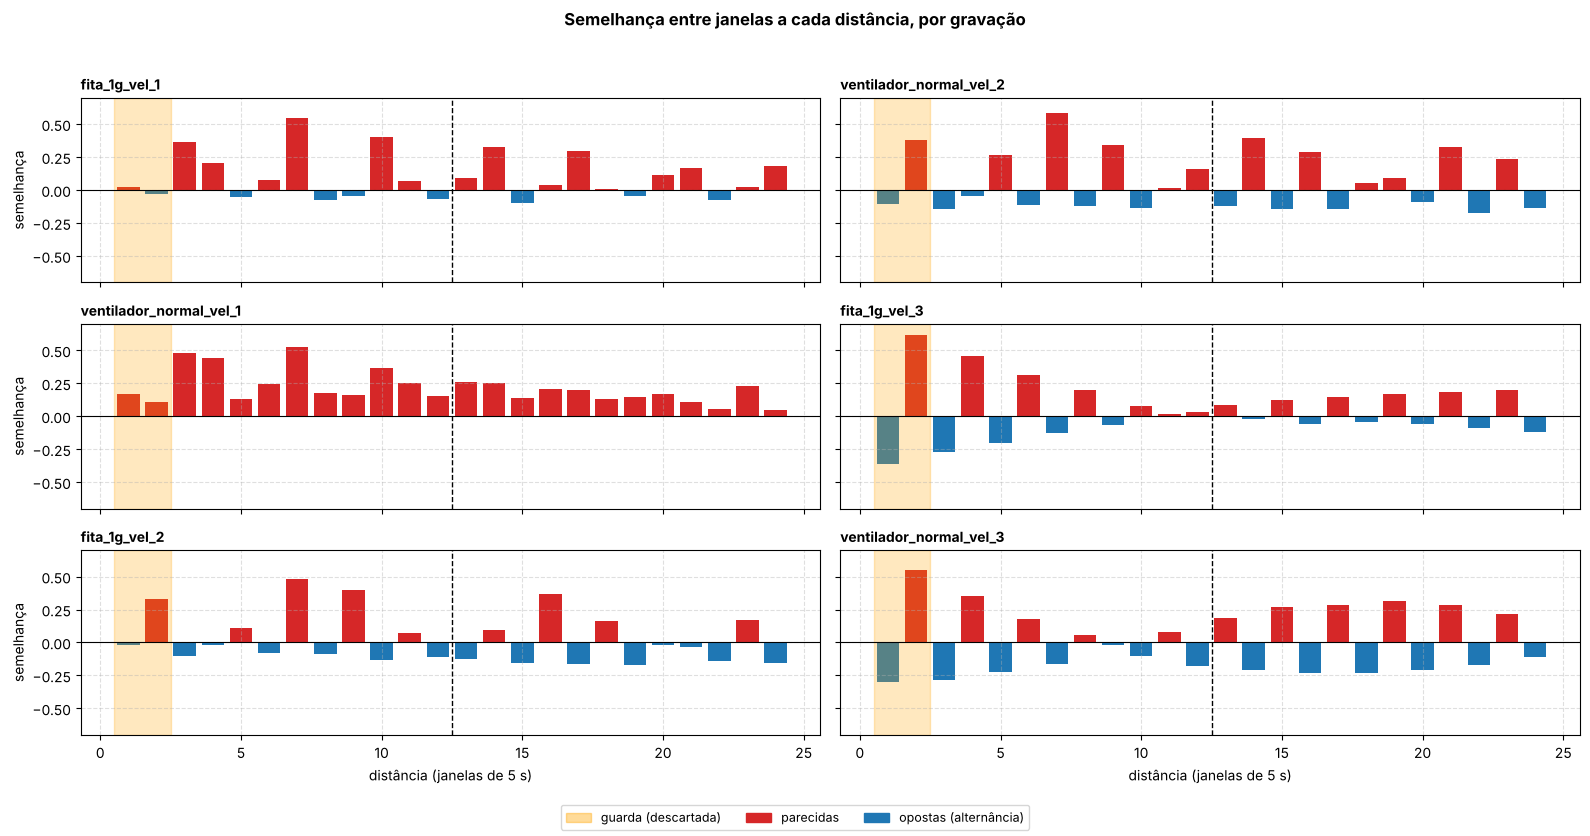

In [12]:
plotar_barras_por_base(curvas_autocorrelacao)

### 3.3 — Matriz de semelhança: cada janela contra cada outra

**O que é:** os dois gráficos anteriores resumem a semelhança por **distância**. Esta figura mostra **todos os pares de janelas** de uma gravação. A célula (linha i, coluna j) diz o quanto a janela i se parece com a janela j, comparando as 109 features (depois do log, padronizadas dentro da gravação).

**Como ler:**

* **A diagonal** é sempre vermelho-escura: cada janela é idêntica a ela mesma.
* **Faixa vermelha larga ao redor da diagonal:** janelas próximas no tempo são parecidas.
* **Dois quadrados grandes** (um no canto superior esquerdo e outro no inferior direito), com azul entre eles: a gravação **muda de comportamento no meio**. O começo parece com o começo, o fim com o fim, mas um não parece com o outro (deriva ou mudança de regime).
* **Listras diagonais paralelas:** o padrão se **repete** a uma distância fixa (o ciclo da oscilação).
* **Xadrez fino:** janelas vizinhas **alternam** (uma forte, outra fraca).
* **As linhas pretas** marcam os blocos de `BLOCO_JANELAS` janelas. Um bloco vira um pequeno quadrado: o que importa é que os quadrados de treino e de teste não "colem" um do outro pela borda, e é para isso que serve a guarda.

In [13]:
def matriz_de_semelhanca(features, base, colunas):
    """Correlação entre os vetores de features de cada par de janelas de uma gravação (log e padronização na gravação)."""
    grupo = features[features["base"] == base].sort_values("janela")
    valores = grupo[colunas].astype(float)
    com_log = [c for c in colunas if c not in COLUNAS_SEM_LOG]
    valores[com_log] = np.log(valores[com_log])
    padronizado = (valores - valores.mean()) / valores.std().replace(0, 1)
    return np.corrcoef(padronizado.to_numpy())


def plotar_matrizes_de_semelhanca(features, colunas, bloco_janelas=BLOCO_JANELAS):
    """Uma matriz janela x janela por gravação, com as fronteiras dos blocos."""
    bases = ordenar_bases(features["base"].unique())
    colunas_fig = 3
    linhas = int(np.ceil(len(bases) / colunas_fig))
    fig, axs = plt.subplots(linhas, colunas_fig, figsize=(6 * colunas_fig, 5.6 * linhas), squeeze=False)
    for ax, base in zip(axs.ravel(), bases):
        matriz = matriz_de_semelhanca(features, base, colunas)
        imagem = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
        for inicio in range(bloco_janelas, len(matriz), bloco_janelas):
            ax.axhline(inicio - 0.5, color="black", linewidth=0.5)
            ax.axvline(inicio - 0.5, color="black", linewidth=0.5)
        ax.set_title(base, fontsize=11, fontweight="bold")
        ax.set_xlabel("janela")
        ax.set_ylabel("janela")
        ax.grid(False)
    for ax in axs.ravel()[len(bases):]:
        ax.axis("off")
    fig.colorbar(imagem, ax=axs.ravel().tolist(), label="semelhança entre as duas janelas", shrink=0.6)
    fig.suptitle(f"Quanto cada janela se parece com cada outra (linhas pretas = blocos de {bloco_janelas * JANELA_S} s)",
                 fontsize=12, fontweight="bold")
    plt.show()

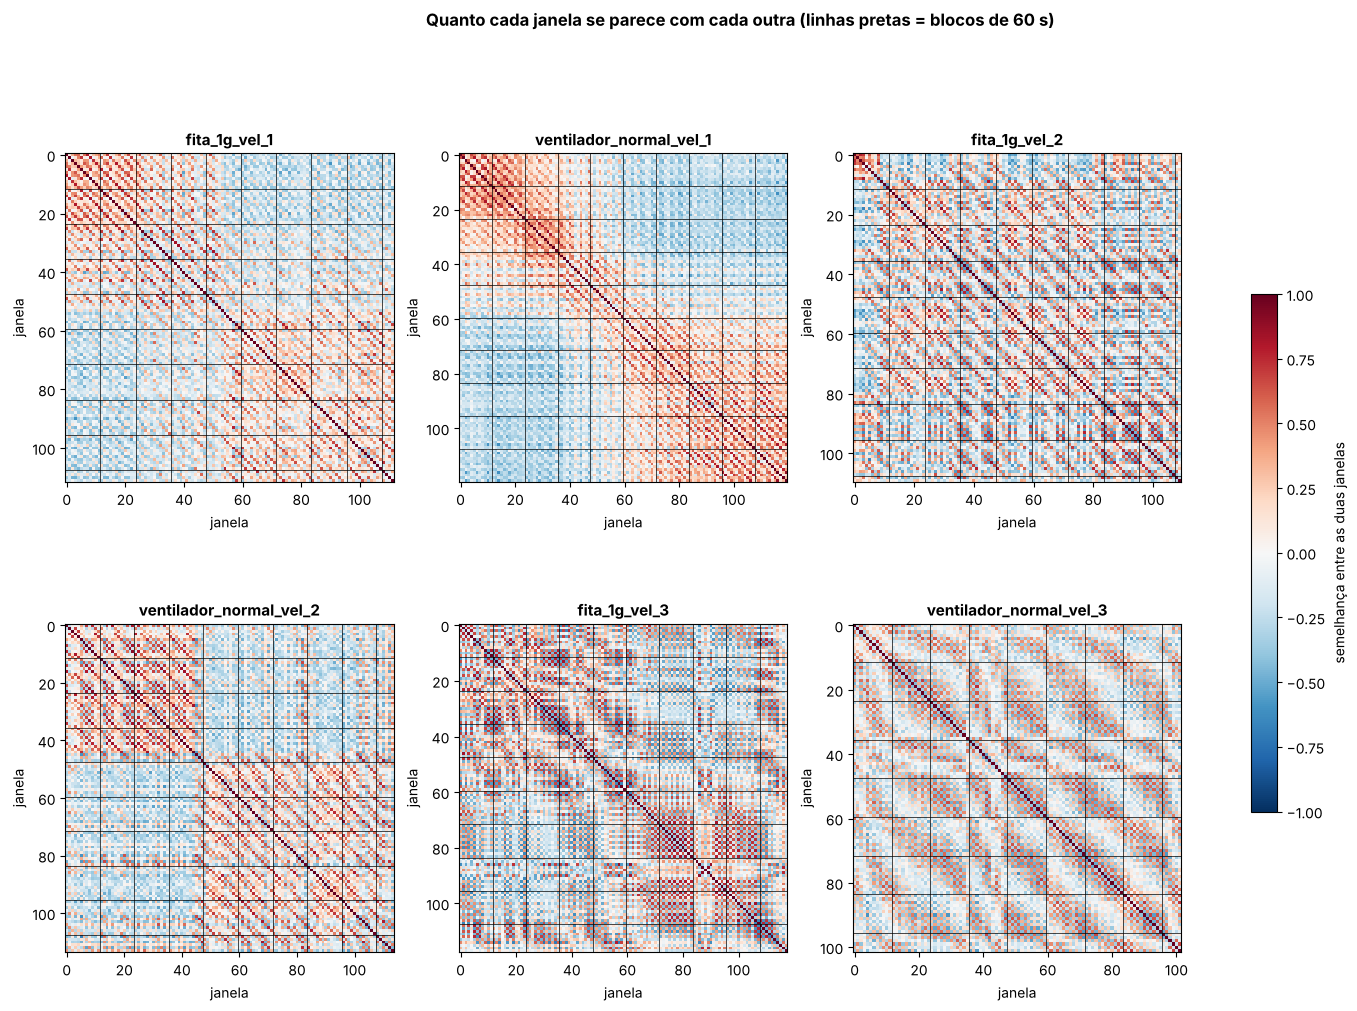

In [14]:
plotar_matrizes_de_semelhanca(features, COLUNAS_TODAS)

### O que as três figuras mostram e por que escolhemos estes valores (nesta execução)

**1. As vizinhas imediatas são parecidas (mapa e barras, lags 1 e 2).** Na Vel 3 a janela a 10 s de distância (lag 2) tem semelhança de **+0,6** (fita) e **+0,5** (normal), e a vizinha direta (lag 1) é **oposta** (−0,4 e −0,3). Nas barras isso aparece como **vermelho e azul alternando**: janela forte, fraca, forte... É o ciclo da oscilação (~10 s) cortado em janelas de 5 s. Na matriz da fita V3 isso aparece como um **xadrez fino**. **É esse vazamento que a guarda resolve:** com `GUARDA_JANELAS = 2`, nenhuma janela de treino fica a menos de 10 s de uma de teste.

**2. A semelhança não some com a distância: ela volta.** No mapa há uma **coluna vermelha em 7 janelas (35 s)**, com +0,5 a +0,6 em fita V1 e V2 e normal V1 e V2. Nas barras são os picos isolados, e na matriz as **listras diagonais paralelas**. É o ciclo da oscilação voltando à mesma fase. **Nenhuma guarda remove isso, e nem precisa:** é a máquina repetindo o próprio padrão, e isso vai continuar acontecendo nos dados futuros. Uma janela parecer com outra de 35 s atrás não é "colar".

**3. Duas gravações do Normal mudam de comportamento no meio (matriz de semelhança):**

* **Normal Vel 1:** a matriz forma **dois quadrados grandes** (início e fim) com azul entre eles. Nas barras, só vermelho, diminuindo devagar: **deriva lenta**. É a mudança de rotação já vista no Notebook 02: a mediana de `f1x_hz` vai de **11,8 Hz** (janelas 0–47) para **13,3 Hz** (janelas 48 em diante).
* **Normal Vel 2:** também há **dois quadrados**, com a troca **por volta da janela 48 (~4 min de gravação)**. Aqui a rotação **cai um pouco**: a mediana de `f1x_hz` vai de **19,6 Hz** para **19,2 Hz**. A mudança é pequena, mas a matriz deixa claro que **a gravação tem duas fases**. Isso não tinha aparecido nos notebooks anteriores. **A causa é desconhecida** (variação da rede elétrica? aquecimento?); vale perguntar ao grupo se algo aconteceu durante a gravação.

* **Fita Vel 1:** mostra algo parecido, mais fraco (o início se parece mais com o início).
* **Normal Vel 3:** é o exemplo "limpo": **listras diagonais regulares** (o ciclo se repetindo) e nenhum quadrado grande, ou seja, sem deriva.

**Por que isso importa para a divisão:** como os blocos sorteados para teste caem nas duas fases, o modelo vê as duas no treino. Mas se a nova coleta tiver mudanças assim **entre** sessões, o teste em outra sessão vai ser mais difícil que o daqui.

**Por isso:**

| Escolha | Valor | Por quê |
| --- | --- | --- |
| Guarda | 2 janelas (10 s) | Remove a vizinhança imediata (lags 1–2), a mais parecida; equivale a ~1 ciclo da oscilação |
| Bloco | 12 janelas (60 s) | Cobre ~5 ciclos da oscilação, então **cada bloco contém todas as fases** (forte e fraca); gera 9–10 blocos por gravação, o suficiente para 5 rodadas de validação e para o teste trancado |

## Passo 4 — Cortar em blocos e separar o teste trancado

**O que o código faz:**

1. **Corta cada gravação em blocos** de `BLOCO_JANELAS` janelas seguidas (por exemplo, 12 janelas = 60 s). Se sobrar um pedaço no fim menor que meio bloco, ele é juntado ao bloco anterior.
2. **Sorteia, em cada gravação, `BLOCOS_TRANCADOS_POR_BASE` blocos** para o **teste trancado**. O sorteio é por gravação, para que **todas as classes** (velocidade × condição) apareçam no teste trancado na mesma proporção. A semente é fixa, então o sorteio é sempre o mesmo.
3. **Marca a guarda:** as `GUARDA_JANELAS` janelas de cada lado de um bloco trancado são descartadas. Elas não entram nem no treino nem no teste.
4. **O resto é o conjunto de desenvolvimento**, onde todos os modelos são treinados e comparados (Passos 5 a 11).

**Por que um teste trancado, se já existe validação cruzada?** Durante o notebook vamos comparar modelos, conjuntos de features e arquiteturas na validação cruzada, e **escolher** os melhores. Cada escolha usa a validação para decidir, e por isso ela fica um pouco "otimista": escolhemos justamente o que foi melhor **nela**. O teste trancado **não participa de nenhuma escolha**. É o único número que mede o modelo escolhido em dados que ninguém olhou. É como a prova final: os simulados (validação) servem para estudar; a prova (trancado) mede o resultado.

**Por que blocos sorteados ao longo da gravação, e não "o final de cada gravação"?** Sortear blocos espalhados representa a gravação inteira (início, meio e fim). Testar só no final mediria também a **deriva** ao longo do tempo (como o aquecimento da Vel 1), que é outra pergunta. Ela tem seu próprio teste no Passo 11 (divisão cronológica).

**O que vem a seguir:** uma tabela com quantas janelas de cada classe foram para cada papel, a lista dos blocos sorteados (com o trecho de tempo de cada um) e o mapa dos blocos (4.1).

In [15]:
def numerar_blocos(features, bloco_janelas=BLOCO_JANELAS):
    """Número do bloco de cada janela, dentro da sua gravação. Sobra menor que meio bloco vai para o bloco anterior."""
    blocos = features["janela"] // bloco_janelas
    for base, grupo in features.groupby("base"):
        ultimo = blocos[grupo.index].max()
        tamanho_ultimo = (blocos[grupo.index] == ultimo).sum()
        if ultimo > 0 and tamanho_ultimo < bloco_janelas / 2:
            blocos[grupo.index[blocos[grupo.index] == ultimo]] = ultimo - 1
    return blocos


def marcar_guarda(features, em_teste, guarda=GUARDA_JANELAS):
    """True nas janelas que NÃO estão em teste mas ficam a até 'guarda' janelas de uma janela de teste da mesma gravação."""
    perto = pd.Series(False, index=features.index)
    for base, grupo in features.groupby("base"):
        janelas_teste = grupo.loc[em_teste[grupo.index], "janela"].to_numpy()
        if len(janelas_teste) == 0:
            continue
        distancia = np.abs(grupo["janela"].to_numpy()[:, None] - janelas_teste[None, :]).min(axis=1)
        perto[grupo.index] = (distancia <= guarda) & ~em_teste[grupo.index].to_numpy()
    return perto


def sortear_teste_trancado(features, blocos_por_base=BLOCOS_TRANCADOS_POR_BASE, semente=SEMENTE):
    """Sorteia, em cada gravação, os blocos do teste trancado. Devolve o papel de cada janela."""
    gerador = np.random.default_rng(semente)
    trancado = pd.Series(False, index=features.index)
    for base, grupo in features.groupby("base"):
        blocos_da_base = np.sort(grupo["bloco"].unique())
        escolhidos = gerador.choice(blocos_da_base, size=min(blocos_por_base, len(blocos_da_base) - 1), replace=False)
        trancado[grupo.index] = grupo["bloco"].isin(escolhidos).to_numpy()
    guarda = marcar_guarda(features, trancado)
    return pd.Series(np.select([trancado, guarda], ["trancado", "guarda"], "desenvolvimento"), index=features.index)

In [16]:
features["bloco"] = numerar_blocos(features)
features["papel"] = sortear_teste_trancado(features)
features["nome_classe"] = "Vel " + features["velocidade"].astype(str) + " - " + features["rotulo_condicao"]

tabela_papeis = pd.crosstab(features["nome_classe"], features["papel"], margins=True, margins_name="Total")
tabela_papeis = tabela_papeis[["desenvolvimento", "trancado", "guarda", "Total"]]
display(tabela_papeis)

blocos_trancados = features[features["papel"] == "trancado"].groupby("nome_classe")["bloco"].unique().apply(lambda b: sorted(int(x) for x in b))
print("Blocos sorteados para o teste trancado (número do bloco dentro da gravação):")
for classe, blocos_da_classe in blocos_trancados.items():
    inicio = [f"{b * BLOCO_JANELAS * JANELA_S}–{(b + 1) * BLOCO_JANELAS * JANELA_S} s" for b in blocos_da_classe]
    print(f"  {classe}: blocos {list(blocos_da_classe)} ({', '.join(inicio)})")

papel,desenvolvimento,trancado,guarda,Total
nome_classe,,,,
Vel 1 - fita_1g,82,24,6,112
Vel 1 - normal,90,24,6,120
Vel 2 - fita_1g,78,26,6,110
Vel 2 - normal,86,24,4,114
Vel 3 - fita_1g,88,24,6,118
Vel 3 - normal,70,24,8,102
Total,494,146,36,676


Blocos sorteados para o teste trancado (número do bloco dentro da gravação):
  Vel 1 - fita_1g: blocos [0, 6] (0–60 s, 360–420 s)
  Vel 1 - normal: blocos [0, 5] (0–60 s, 300–360 s)
  Vel 2 - fita_1g: blocos [3, 8] (180–240 s, 480–540 s)
  Vel 2 - normal: blocos [6, 7] (360–420 s, 420–480 s)
  Vel 3 - fita_1g: blocos [0, 6] (0–60 s, 360–420 s)
  Vel 3 - normal: blocos [4, 6] (240–300 s, 360–420 s)


### 4.1 — Mapa dos blocos

**Como ler:** cada linha é uma classe (uma gravação), e cada quadradinho é uma janela de 5 s, posicionada no **tempo dentro da gravação** (em segundos). A cor diz para onde a janela foi:

* **azul (desenvolvimento):** usada para treinar e comparar modelos (Passos 5 a 11);
* **laranja (teste trancado):** guardada até o Passo 12;
* **cinza (guarda):** descartada, é o "fosso" que separa o teste trancado do resto.

As linhas verticais finas marcam a fronteira de cada bloco de 60 s.

**Diferença em relação ao notebook antigo:** lá, a guarda era colocada **entre todos os blocos**, o que descartava 108 janelas. Aqui ela só aparece **onde treino e teste se encostam**: em volta dos blocos trancados (este mapa) e em volta dos blocos de validação de cada rodada (Passo 5). A proteção é a mesma e perdemos menos dados.

In [17]:
CORES_PAPEL = {"desenvolvimento": "tab:blue", "trancado": "tab:orange", "guarda": "lightgray"}


def plotar_mapa_de_blocos(features, papeis, titulo, cores=CORES_PAPEL, ax=None):
    """Uma linha por classe; cada janela é um quadrado no seu instante dentro da gravação, colorido pelo papel."""
    papeis = pd.Series(np.asarray(papeis), index=features.index)
    classes = sorted(features["nome_classe"].unique(), key=lambda c: (c.split(" - ")[0], c.split(" - ")[1] != NOME_NORMAL), reverse=True)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(15, 0.65 * len(classes) + 1.6))
    for papel, cor in cores.items():
        sel = (papeis == papel).to_numpy()
        y = [classes.index(c) for c in features.loc[sel, "nome_classe"]]
        ax.scatter(features.loc[sel, "janela"] * JANELA_S, y, marker="s", s=22, color=cor, label=papel)
    for i, classe in enumerate(classes):
        grupo = features[features["nome_classe"] == classe]
        for inicio in grupo.groupby("bloco")["janela"].min().to_numpy()[1:]:
            ax.plot([inicio * JANELA_S - JANELA_S / 2] * 2, [i - 0.3, i + 0.3], color="black", linewidth=0.6)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=9)
    ax.set_ylim(-0.6, len(classes) - 0.4)
    ax.set_xlabel("tempo dentro da gravação (segundos)")
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18 if criou else -0.25), ncol=len(cores), fontsize=9, markerscale=1.3)
    if criou:
        plt.tight_layout()
        plt.show()

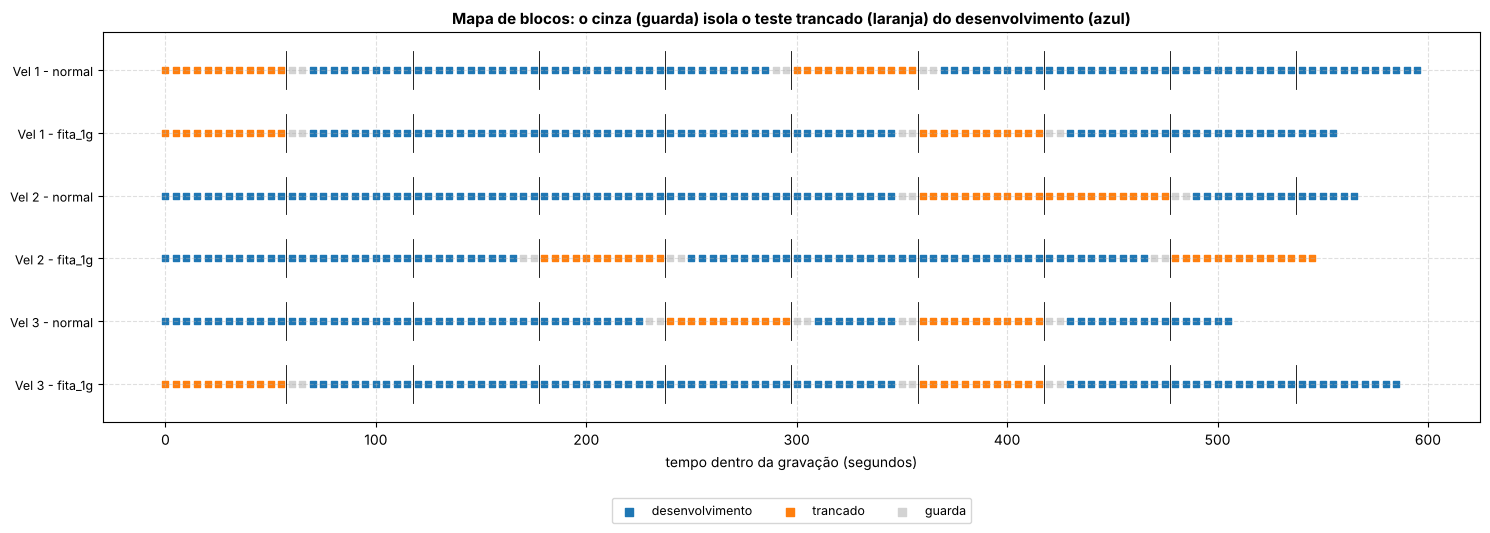

In [18]:
plotar_mapa_de_blocos(features, features["papel"], "Mapa de blocos: o cinza (guarda) isola o teste trancado (laranja) do desenvolvimento (azul)")

### Como ficou a divisão (nesta execução)

* **Cada gravação virou 9 ou 10 blocos de 60 s.** De cada uma, 2 blocos foram sorteados para o teste trancado (24 a 26 janelas por gravação).
* **Total:** 494 janelas de desenvolvimento, **146 no teste trancado (22%)** e 36 descartadas na guarda (os quadrados cinza do mapa). No notebook antigo eram 457 de treino, 111 no trancado e 108 na guarda: aqui a guarda só aparece onde treino e teste se encostam, então sobram mais janelas para treinar.
* **O sorteio caiu em lugares variados:** início (bloco 0 de fita V1, normal V1 e fita V3), meio e fim. No normal V2 os dois blocos sorteados ficaram vizinhos (6 e 7). Como o sorteio é aleatório e a semente é fixa, isso não foi escolhido por nós.
* **Todas as 6 classes estão no trancado com o mesmo peso** (2 blocos de cada gravação).

## Passo 5 — Validação cruzada por blocos: como comparar modelos sem tocar no trancado

**O que é:** dividimos os blocos do conjunto de desenvolvimento em `N_FOLDS` grupos (folds). Em cada rodada, **um fold é a validação** e os outros são o treino. Repetimos até que cada fold tenha sido validação uma vez. Assim, **toda janela de desenvolvimento é prevista uma vez por um modelo que não a viu**, e juntamos essas previsões numa única matriz de confusão.

**Três regras para ser honesto:**

1. **Blocos inteiros:** um bloco nunca fica dividido entre treino e validação.
2. **Estratificado:** cada fold recebe blocos de todas as 6 classes, para não haver um fold sem nenhuma fita da Vel 1, por exemplo (`StratifiedGroupKFold`).
3. **Guarda dentro de cada rodada:** as `GUARDA_JANELAS` janelas vizinhas aos blocos de validação são retiradas do **treino daquela rodada**.

**Como ler a figura:** um painel por rodada, no mesmo formato do mapa do Passo 4. Em cada um: **verde** = validação da rodada, **azul** = treino da rodada, **cinza** = guarda (as vizinhas da validação, retiradas do treino daquela rodada, mais a guarda do trancado) e **bege** = teste trancado, que não aparece em nenhuma rodada. Repare que **cada bloco fica verde em exatamente uma rodada**.

In [19]:
def montar_folds(dev, n_folds=N_FOLDS, semente=SEMENTE):
    """Folds por blocos, estratificados pela classe, com guarda retirada do treino. Índices referem-se a 'dev'."""
    grupos = dev["base"] + "|" + dev["bloco"].astype(str)
    divisor = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=semente)
    folds = []
    for treino, validacao in divisor.split(dev, dev["rotulo_classe"], groups=grupos):
        em_validacao = pd.Series(False, index=dev.index)
        em_validacao.iloc[validacao] = True
        guarda = marcar_guarda(dev, em_validacao)
        treino_limpo = np.where(~em_validacao.to_numpy() & ~guarda.to_numpy())[0]
        folds.append((treino_limpo, validacao, np.where(guarda.to_numpy())[0]))
    return folds

In [20]:
dev = features[features["papel"] == "desenvolvimento"].copy()
trancado = features[features["papel"] == "trancado"].copy()
folds = montar_folds(dev)

for k, (treino, validacao, guarda) in enumerate(folds, start=1):
    classes_na_validacao = dev.iloc[validacao]["rotulo_classe"].nunique()
    print(f"Rodada {k}: treino {len(treino)} janelas | validação {len(validacao)} | guarda retirada {len(guarda)} | "
          f"classes na validação: {classes_na_validacao} de {len(ORDEM_CLASSES)}")

Rodada 1: treino 366 janelas | validação 100 | guarda retirada 28 | classes na validação: 6 de 6
Rodada 2: treino 358 janelas | validação 108 | guarda retirada 28 | classes na validação: 6 de 6
Rodada 3: treino 380 janelas | validação 92 | guarda retirada 22 | classes na validação: 6 de 6
Rodada 4: treino 382 janelas | validação 92 | guarda retirada 20 | classes na validação: 6 de 6
Rodada 5: treino 370 janelas | validação 102 | guarda retirada 22 | classes na validação: 6 de 6


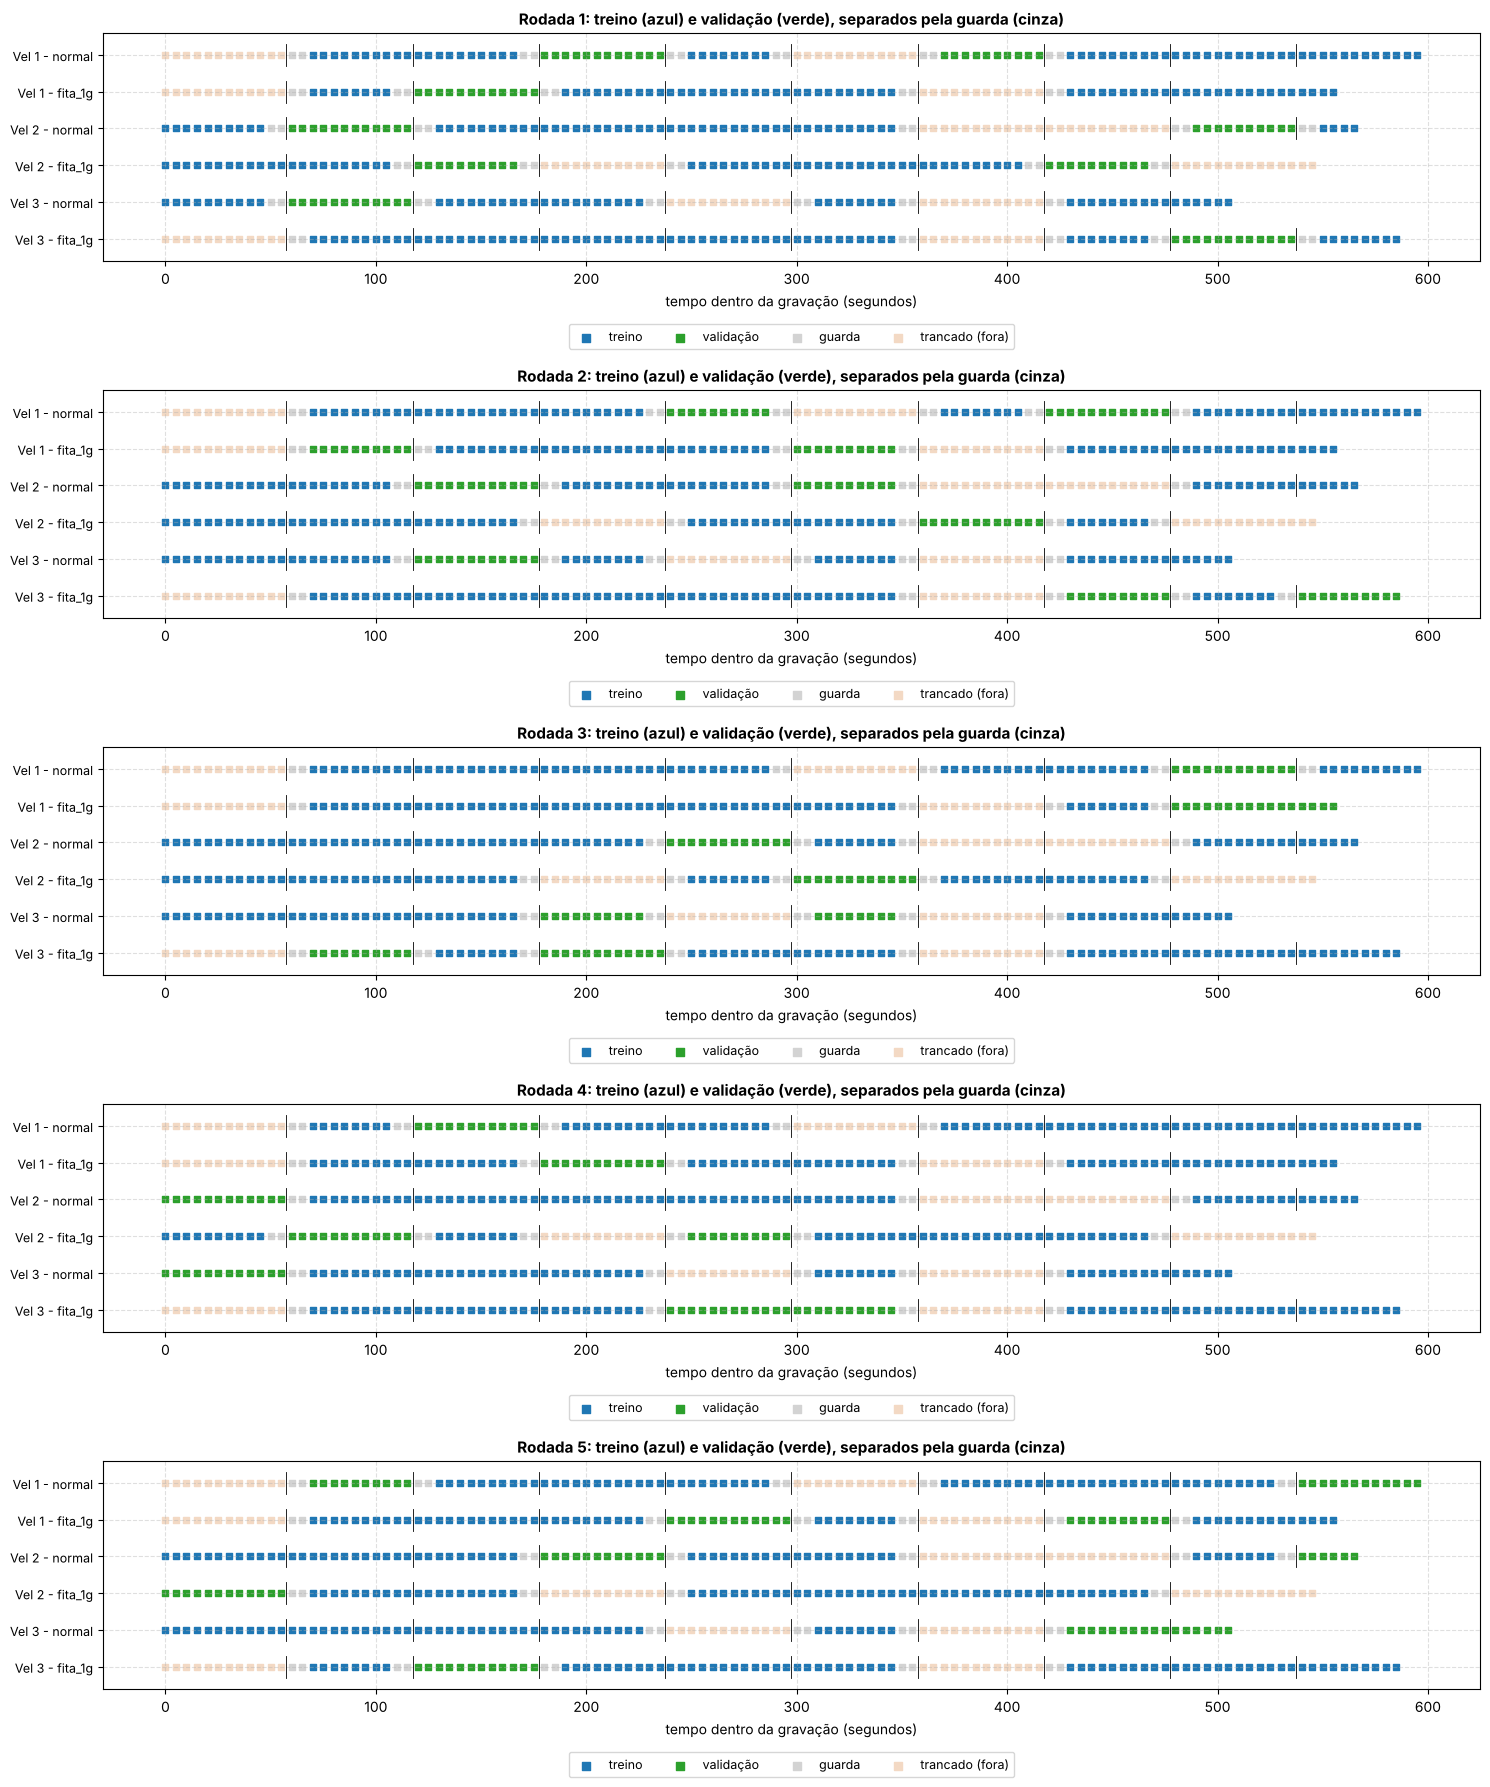

In [21]:
CORES_RODADA = {"treino": "tab:blue", "validação": "tab:green", "guarda": "lightgray", "trancado (fora)": "#f3d9c4"}
fig, axs = plt.subplots(len(folds), 1, figsize=(15, 3.6 * len(folds)))
for k, (ax, (treino, validacao, guarda)) in enumerate(zip(np.atleast_1d(axs), folds), start=1):
    papeis = np.full(len(features), "trancado (fora)", dtype=object)
    papeis[features.index.get_indexer(dev.index[treino])] = "treino"
    papeis[features.index.get_indexer(dev.index[validacao])] = "validação"
    papeis[features.index.get_indexer(dev.index[guarda])] = "guarda"
    papeis[(features["papel"] == "guarda").to_numpy()] = "guarda"
    plotar_mapa_de_blocos(features, papeis, f"Rodada {k}: treino (azul) e validação (verde), separados pela guarda (cinza)",
                          cores=CORES_RODADA, ax=ax)
plt.tight_layout()
plt.show()

## Passo 6 — Pipeline: log → scaler → modelo, com o scaler ajustado só no treino

**O vazamento que o Notebook 04 tinha (e que aqui não pode ter):** lá, o scaler calculava média e desvio usando **todas** as janelas, inclusive as que depois eram avaliadas. Se a média for calculada com janelas de teste, o modelo recebe uma "dica" sobre elas. Aqui, **média e desvio vêm só das janelas de treino de cada rodada** e são aplicados, sem recalcular, às janelas de validação.

**Como garantimos isso:** com um `Pipeline` do scikit-learn, uma "esteira" com três etapas:

1. **Log** nas features (menos a curtose), como nos Notebooks 03 e 04. O log não aprende nada, é a mesma conta para todo mundo.
2. **StandardScaler**, que aprende média e desvio **no `fit` (treino)** e só aplica no `predict` (validação/teste).
3. **O modelo.**

Quando chamamos `pipeline.fit(treino)`, as três etapas aprendem só com o treino. Quando chamamos `pipeline.predict(teste)`, o teste passa pela esteira já ajustada. **Não há como o teste vazar para o ajuste.**

**E o scaler local?** Na arquitetura em duas etapas (Tarefa C), o detector de cada velocidade tem seu próprio pipeline, treinado só com as janelas daquela velocidade. Então o scaler dele é **local por construção**, e também ajustado só no treino.

In [22]:
def criar_pipeline(modelo, colunas):
    """Esteira log -> StandardScaler -> modelo. Log em todas as colunas menos COLUNAS_SEM_LOG."""
    com_log = [c for c in colunas if c not in COLUNAS_SEM_LOG]
    sem_log = [c for c in colunas if c in COLUNAS_SEM_LOG]
    preparo = ColumnTransformer([("log", FunctionTransformer(np.log), com_log), ("sem_log", "passthrough", sem_log)])
    return Pipeline([("log", preparo), ("scaler", StandardScaler()), ("modelo", modelo)])


class DuasEtapas(BaseEstimator, ClassifierMixin):
    """Arquitetura em duas etapas: prevê a velocidade, depois usa o detector daquela velocidade.

    Os rótulos de treino são as classes no formato '<condição> <velocidade>' (por exemplo 'normal V2').
    Cada etapa é um pipeline completo (log -> scaler -> modelo), então cada detector tem o seu scaler local.
    """
    def __init__(self, pipeline_velocidade, pipeline_condicao):
        self.pipeline_velocidade = pipeline_velocidade
        self.pipeline_condicao = pipeline_condicao

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        velocidade = y.str.rsplit(" ", n=1).str[1]
        condicao = y.str.rsplit(" ", n=1).str[0]
        self.etapa1_ = clone(self.pipeline_velocidade).fit(X, velocidade)
        self.etapa2_ = {}
        for v in velocidade.unique():
            sel = (velocidade == v).to_numpy()
            if condicao[sel].nunique() == 1:
                self.etapa2_[v] = condicao[sel].iloc[0]
            else:
                self.etapa2_[v] = clone(self.pipeline_condicao).fit(X[sel], condicao[sel])
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        velocidade = self.etapa1_.predict(X)
        condicao = np.empty(len(X), dtype=object)
        for v in np.unique(velocidade):
            sel = velocidade == v
            detector = self.etapa2_.get(v)
            condicao[sel] = detector if isinstance(detector, str) else detector.predict(X[sel])
        return np.array([f"{c} {v}" for c, v in zip(condicao, velocidade)])

## Passo 7 — Métricas e modelos

### A acurácia balanceada

Além das métricas do Notebook 04 (matriz de confusão, recall por classe, falso alarme), usamos a **acurácia balanceada**: a **média dos recalls de todas as classes**.

* **Exemplo:** 3 classes com recall de 100%, 100% e 40% → acurácia balanceada = (100 + 100 + 40) / 3 = 80%.
* **Por que usar:** a acurácia comum dá mais peso às classes com mais janelas. A balanceada dá o **mesmo peso a cada classe**, então uma classe mal acertada sempre puxa a nota para baixo. É o critério de escolha dos modelos.

### Os modelos

**Referências ("modelos burros"), para saber o quanto o problema é fácil:**

| Modelo | Como funciona | Para que serve |
| --- | --- | --- |
| **Classe mais comum** | Responde sempre a classe com mais janelas no treino | O piso: qualquer modelo útil tem que passar dele com folga |
| **Stump (1 pergunta)** | Uma árvore de decisão com uma pergunta só, por exemplo "`std_y` > 1,2?" | Se 1 pergunta já acerta quase tudo, o problema é fácil, e isso precisa estar no texto |

**Classificadores:**

| Modelo | Como funciona (em uma frase) | Por que está aqui |
| --- | --- | --- |
| **Regressão logística** | Traça fronteiras retas (planos) entre as classes | O mais simples e interpretável; mostra se uma fronteira linear basta |
| **KNN (k=5)** | Olha as 5 janelas de treino mais parecidas e vota | Usado nos notebooks antigos; depende muito da escala (por isso o scaler) |
| **Random Forest** | Centenas de árvores de decisão, cada uma vendo parte dos dados, que votam | Usado nos notebooks antigos; aguenta features de escalas diferentes e mostra quais features usou |
| **SVM (kernel RBF)** | Procura a fronteira que fica o mais longe possível das duas classes, podendo ser curva | Clássico em diagnóstico de máquinas por vibração; bom com poucos dados e muitas features |

**Como ler as tabelas dos Passos 8 a 10:** uma linha por modelo e conjunto de features, com a acurácia balanceada da validação cruzada. As matrizes mostram o melhor modelo e o `CONJUNTO_PRINCIPAL`.

In [23]:
MODELOS = {
    "referência: classe mais comum": lambda: DummyClassifier(strategy="most_frequent"),
    "referência: stump (1 pergunta)": lambda: DecisionTreeClassifier(max_depth=1, random_state=SEMENTE),
    "regressão logística": lambda: LogisticRegression(max_iter=5000),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": lambda: SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
}
ORDEM_SIMPLICIDADE = ["regressão logística", "KNN (k=5)", "SVM (RBF)", "Random Forest"]

In [24]:
def validar(fabrica_modelo, dev, colunas, coluna_rotulo, folds):
    """Validação cruzada por blocos: devolve a previsão de cada janela de 'dev' feita por um modelo que não a viu."""
    previsto = np.empty(len(dev), dtype=object)
    X, y = dev[colunas], dev[coluna_rotulo].to_numpy()
    for treino, validacao, _ in folds:
        modelo = fabrica_modelo().fit(X.iloc[treino], y[treino])
        previsto[validacao] = modelo.predict(X.iloc[validacao])
    return previsto


def metricas(reais, previstos, classes):
    """Acurácia, acurácia balanceada e recall de cada classe."""
    reais, previstos = np.asarray(reais), np.asarray(previstos)
    saida = {"acurácia (%)": 100 * (reais == previstos).mean(),
             "acurácia balanceada (%)": 100 * balanced_accuracy_score(reais, previstos)}
    for classe in classes:
        saida[f"recall {classe} (%)"] = 100 * (previstos[reais == classe] == classe).mean()
    return saida


def plotar_matriz(reais, previstos, classes, titulo, ax=None):
    """Matriz real (linhas) x previsto (colunas): contagem e % da linha. A diagonal é o recall."""
    tabela = pd.crosstab(pd.Series(reais, name="real"), pd.Series(previstos, name="previsto")).reindex(index=classes, columns=classes, fill_value=0)
    porcentagem = 100 * tabela.div(tabela.sum(axis=1).replace(0, np.nan), axis=0)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * len(classes) + 2.5, 1.1 * len(classes) + 1.8))
    ax.imshow(porcentagem.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{tabela.iat[i, j]}\n{porcentagem.iat[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if porcentagem.iat[i, j] > 60 else "black")
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("o modelo disse")
    ax.set_ylabel("é de verdade")
    ax.grid(False)
    ax.set_title(f"{titulo}\nacurácia balanceada {100 * balanced_accuracy_score(reais, previstos):.1f}%", fontsize=10, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()


def comparar_modelos(dev, conjuntos, coluna_rotulo, classes, folds, modelos=MODELOS):
    """Valida todos os modelos em todos os conjuntos. Devolve (tabela, previsões[(modelo, conjunto)])."""
    linhas, previsoes = [], {}
    for nome_conjunto, colunas in conjuntos.items():
        for nome_modelo, fabrica in modelos.items():
            previsto = validar(lambda: criar_pipeline(fabrica(), colunas), dev, colunas, coluna_rotulo, folds)
            previsoes[(nome_modelo, nome_conjunto)] = previsto
            linhas.append({"modelo": nome_modelo, "features": nome_conjunto, **metricas(dev[coluna_rotulo], previsto, classes)})
    return pd.DataFrame(linhas).set_index(["features", "modelo"]), previsoes


def melhor_real(tabela):
    """Melhor modelo não-referência pela acurácia balanceada (regra de empate do Passo 12)."""
    candidatos = tabela[~tabela.index.get_level_values("modelo").str.startswith("referência")]
    return aplicar_regra_de_escolha(candidatos)


def aplicar_regra_de_escolha(candidatos, coluna="acurácia balanceada (%)"):
    """Maior acurácia balanceada; empates (< EMPATE_PP) resolvidos pelo mais simples."""
    melhor = candidatos[coluna].max()
    empatados = candidatos[candidatos[coluna] >= melhor - EMPATE_PP].reset_index()
    ordem_modelo = {m: i for i, m in enumerate(ORDEM_SIMPLICIDADE)}
    ordem_arquitetura = {"classificador único": 0, "duas etapas": 1}
    empatados["_simplicidade"] = list(zip(
        empatados.get("arquitetura", pd.Series(["classificador único"] * len(empatados))).map(ordem_arquitetura).fillna(0),
        empatados["modelo"].map(ordem_modelo).fillna(99),
        empatados["features"].map(lambda f: len(CONJUNTOS_TODOS.get(f, COLUNAS_TODAS)))))
    escolhido = empatados.sort_values("_simplicidade").iloc[0]
    return escolhido.drop("_simplicidade")

## Passo 8 — Tarefa A: qual a velocidade de uma janela?

**O que buscamos:** classificar a velocidade (V1, V2, V3) de **qualquer** janela, normal ou com falha. É a etapa 1 da arquitetura.

**A pergunta que vem do Notebook 04:** lá, a velocidade descoberta sem rótulo colocava **a fita V3 no regime da Vel 2**. Com rótulos, isso deve sumir. Testamos também um conjunto com **só a rotação estimada (`f1x_hz`)**, que em princípio depende só da velocidade e pouco da falha.

**Como ler:** a tabela traz a acurácia balanceada de cada modelo em cada conjunto. A matriz mostra o melhor modelo com o `CONJUNTO_PRINCIPAL`, com as linhas separadas por condição para enxergar se a fita é a que mais erra.

In [25]:
CONJUNTOS_TAREFA_A = {**CONJUNTOS, "só f1x_hz": ["f1x_hz"]}
CONJUNTOS_TODOS = CONJUNTOS_TAREFA_A

tabela_a, previsoes_a = comparar_modelos(dev, CONJUNTOS_TAREFA_A, "rotulo_velocidade", ORDEM_VELOCIDADES, folds)
display(tabela_a.round(1))

acurácia (%)  \
features  modelo                                         
tempo     referência: classe mais comum           32.0   
          referência: stump (1 pergunta)          64.4   
          regressão logística                    100.0   
          KNN (k=5)                               99.6   
          SVM (RBF)                               99.4   
          Random Forest                          100.0   
FFT       referência: classe mais comum           32.0   
          referência: stump (1 pergunta)          64.4   
          regressão logística                    100.0   
          KNN (k=5)                               99.8   
          SVM (RBF)                               99.8   
          Random Forest                          100.0   
rotação   referência: classe mais comum           32.0   
          referência: stump (1 pergunta)          61.1   
          regressão logística                    100.0   
          KNN (k=5)                              100.0   
          SVM (RBF)                              100.0   
          Random Forest                          100.0   
todas     referência: classe mais comum           32.0   
          referência: stump (1 pergunta)          60.5   
          regressão logística                    100.0   
          KNN (k=5)                              100.0   
          SVM (RBF)                              100.0   
          Random Forest                          100.0   
só f1x_hz referência: classe mais comum           32.0   
          referência: stump (1 pergunta)          61.1   
          regressão logística                    100.0   
          KNN (k=5)                              100.0   
          SVM (RBF)                              100.0   
          Random Forest                          100.0   

                                          acurácia balanceada (%)  \
features  modelo                                                    
tempo     referência: classe mais comum                      30.9   
          referência: stump (1 pergunta)                     63.2   
          regressão logística                               100.0   
          KNN (k=5)                                          99.6   
          SVM (RBF)                                          99.4   
          Random Forest                                     100.0   
FFT       referência: classe mais comum                      30.9   
          referência: stump (1 pergunta)                     63.2   
          regressão logística                               100.0   
          KNN (k=5)                                          99.8   
          SVM (RBF)                                          99.8   
          Random Forest                                     100.0   
rotação   referência: classe mais comum                      30.9   
          referência: stump (1 pergunta)                     60.6   
          regressão logística                               100.0   
          KNN (k=5)                                         100.0   
          SVM (RBF)                                         100.0   
          Random Forest                                     100.0   
todas     referência: classe mais comum                      30.9   
          referência: stump (1 pergunta)                     60.0   
          regressão logística                               100.0   
          KNN (k=5)                                         100.0   
          SVM (RBF)                                         100.0   
          Random Forest                                     100.0   
só f1x_hz referência: classe mais comum                      30.9   
          referência: stump (1 pergunta)                     60.6   
          regressão logística                               100.0   
          KNN (k=5)                                         100.0   
          SVM (RBF)                                         100.0   
          Random Forest                       

Melhor modelo em 'todas': regressão logística


velocidade prevista,V1,V2,V3
classe real,,,
normal V1,90,0,0
fita_1g V1,82,0,0
normal V2,0,86,0
fita_1g V2,0,78,0
normal V3,0,0,70
fita_1g V3,0,0,88


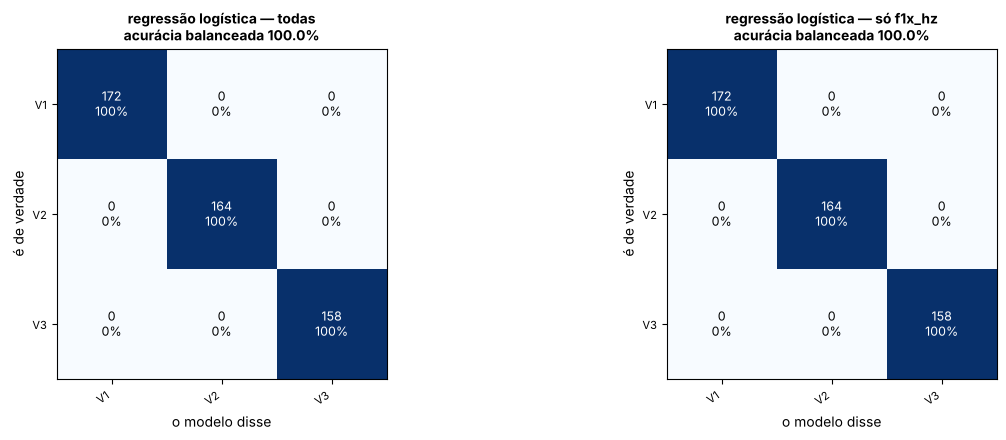

In [26]:
escolha_a = melhor_real(tabela_a.loc[[CONJUNTO_PRINCIPAL]])
previsto = previsoes_a[(escolha_a["modelo"], CONJUNTO_PRINCIPAL)]
print(f"Melhor modelo em '{CONJUNTO_PRINCIPAL}': {escolha_a['modelo']}")

linhas_reais = dev["rotulo_classe"].to_numpy()
tabela_erros = pd.crosstab(pd.Series(linhas_reais, name="classe real"), pd.Series(previsto, name="velocidade prevista")).reindex(ORDEM_CLASSES)
display(tabela_erros)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
plotar_matriz(dev["rotulo_velocidade"].to_numpy(), previsto, ORDEM_VELOCIDADES, f"{escolha_a['modelo']} — {CONJUNTO_PRINCIPAL}", ax=axs[0])
previsto_f1x = previsoes_a[(escolha_a["modelo"], "só f1x_hz")]
plotar_matriz(dev["rotulo_velocidade"].to_numpy(), previsto_f1x, ORDEM_VELOCIDADES, f"{escolha_a['modelo']} — só f1x_hz", ax=axs[1])
plt.tight_layout()
plt.show()

### Conclusões do Passo 8 (nesta execução)

**Com rótulos, a velocidade é acertada em 100%, inclusive na fita.** O problema do Notebook 04 (fita V3 encaixada no regime da Vel 2) **desaparece** quando a velocidade é aprendida com rótulos: a tabela "classe real × velocidade prevista" tem todas as janelas na velocidade certa.

* **Só a rotação estimada (`f1x_hz`), uma feature, já dá 100%** com os quatro classificadores. É a confirmação da ideia do Notebook 04: a etapa de velocidade pode usar só o que depende da velocidade e não da falha.
* **Mas atenção à Vel 1:** nos dados atuais a rotação do Normal da Vel 1 variou durante a gravação (~11 → 13,8 Hz), e mesmo assim não houve confusão. Se nos dados novos as faixas de rotação de duas velocidades se encostarem, `f1x_hz` sozinha pode falhar. Vale reexecutar com a nova coleta.
* **Os modelos de referência ficam longe:** chutar a classe mais comum dá 31% e o stump, 60%. A tarefa não é trivial, mas é fácil para qualquer classificador de verdade.

## Passo 9 — Tarefa B: normal ou anomalia?

**O que buscamos:** a detecção supervisionada: um modelo que viu exemplos de normal **e** de fita no treino, de todas as velocidades juntas, sem receber a velocidade.

**Lembrete do Notebook 04:** o K=2 global sem rótulos não detectou nada da fita na Vel 1. Com rótulos, o modelo pode aprender a fronteira certa mesmo que a fita V1 esteja perto do normal.

**Como ler:** além da acurácia balanceada, olhe o **recall da anomalia em cada velocidade** e o **falso alarme**. É a pergunta da manutenção: "quanta falha passa despercebida, e quantas vezes acusamos o ventilador bom?".

In [27]:
def recall_por_velocidade(dev, previsto_binario):
    """Recall da anomalia por velocidade e falso alarme por velocidade."""
    linhas = []
    for v in ORDEM_VELOCIDADES:
        sel = (dev["rotulo_velocidade"] == v).to_numpy()
        reais = dev["rotulo_binario"].to_numpy()[sel]
        prev = np.asarray(previsto_binario)[sel]
        linhas.append({"velocidade": v,
                       f"recall {NOME_ANOMALIA} (%)": 100 * (prev[reais == NOME_ANOMALIA] == NOME_ANOMALIA).mean(),
                       "falso alarme (%)": 100 * (prev[reais == NOME_NORMAL] == NOME_ANOMALIA).mean()})
    return pd.DataFrame(linhas).set_index("velocidade")

acurácia (%)  \
features modelo                                         
tempo    referência: classe mais comum           44.5   
         referência: stump (1 pergunta)          83.4   
         regressão logística                     94.5   
         KNN (k=5)                               99.6   
         SVM (RBF)                               99.8   
         Random Forest                          100.0   
FFT      referência: classe mais comum           44.5   
         referência: stump (1 pergunta)          95.1   
         regressão logística                    100.0   
         KNN (k=5)                              100.0   
         SVM (RBF)                              100.0   
         Random Forest                          100.0   
rotação  referência: classe mais comum           44.5   
         referência: stump (1 pergunta)          81.4   
         regressão logística                     99.6   
         KNN (k=5)                              100.0   
         SVM (RBF)                              100.0   
         Random Forest                          100.0   
todas    referência: classe mais comum           44.5   
         referência: stump (1 pergunta)          95.1   
         regressão logística                    100.0   
         KNN (k=5)                              100.0   
         SVM (RBF)                              100.0   
         Random Forest                          100.0   

                                         acurácia balanceada (%)  \
features modelo                                                    
tempo    referência: classe mais comum                      44.5   
         referência: stump (1 pergunta)                     83.5   
         regressão logística                                94.5   
         KNN (k=5)                                          99.6   
         SVM (RBF)                                          99.8   
         Random Forest                                     100.0   
FFT      referência: classe mais comum                      44.5   
         referência: stump (1 pergunta)                     95.1   
         regressão logística                               100.0   
         KNN (k=5)                                         100.0   
         SVM (RBF)                                         100.0   
         Random Forest                                     100.0   
rotação  referência: classe mais comum                      44.5   
         referência: stump (1 pergunta)                     81.4   
         regressão logística                                99.6   
         KNN (k=5)                                         100.0   
         SVM (RBF)                                         100.0   
         Random Forest                                     100.0   
todas    referência: classe mais comum                      44.5   
         referência: stump (1 pergunta)                     95.1   
         regressão logística                               100.0   
         KNN (k=5)                                         100.0   
         SVM (RBF)                                         100.0   
         Random Forest                                     100.0   

                                         recall normal (%)  \
features modelo                                              
tempo    referência: classe mais comum                31.7   
         referência: stump (1 pergunta)              100.0   
         regressão logística                          96.7   
         KNN (k=5)                                    99.2   
         SVM (RBF)                                    99.6   
         Random Forest                               100.0   
FFT      referência: classe mais comum                31.7   
         referência: stump (1 pergunta)               93.5   
         regressão logística                         100.0   
         KNN (k=5)                                   100.0   
         SVM (RBF)                           

Melhor modelo em 'todas': regressão logística


,recall anomalia (%),falso alarme (%)
velocidade,,
V1,100.0,0.0
V2,100.0,0.0
V3,100.0,0.0


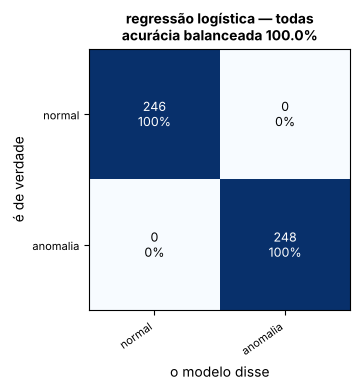

In [28]:
CLASSES_BINARIAS = [NOME_NORMAL, NOME_ANOMALIA]
tabela_b, previsoes_b = comparar_modelos(dev, CONJUNTOS, "rotulo_binario", CLASSES_BINARIAS, folds)
display(tabela_b.round(1))

escolha_b = melhor_real(tabela_b.loc[[CONJUNTO_PRINCIPAL]])
previsto = previsoes_b[(escolha_b["modelo"], CONJUNTO_PRINCIPAL)]
print(f"Melhor modelo em '{CONJUNTO_PRINCIPAL}': {escolha_b['modelo']}")
display(recall_por_velocidade(dev, previsto).round(1))
plotar_matriz(dev["rotulo_binario"].to_numpy(), previsto, CLASSES_BINARIAS, f"{escolha_b['modelo']} — {CONJUNTO_PRINCIPAL}")

### Conclusões do Passo 9 (nesta execução)

**Com rótulos, normal e fita se separam com 99,6% a 100%, inclusive na Vel 1**, que o K=2 global do Notebook 04 não detectava (0%). Agora a fronteira é aprendida com exemplos e não depende de a fita V1 estar "longe".

* **Um modelo de 1 pergunta já acerta 95,1%:** o stump pergunta se a FFT de **25 a 35 Hz no eixo y** passa de um limite (Passo 11.3). **A tarefa é fácil**, e isso precisa estar no texto: com a fita, uma única faixa do espectro quase resolve.
* **Com só as features de tempo**, a regressão logística cai para 94,5%: uma fronteira reta com 9 features não basta. Os modelos não lineares (KNN, SVM, Random Forest) chegam a 99,6–100%.
* **Falso alarme de 0% e recall de 100%** nas três velocidades, no melhor modelo.

## Passo 10 — Tarefa C: as 6 classes, com um classificador único ou em duas etapas

**O que buscamos:** prever velocidade **e** condição ao mesmo tempo, comparando as duas arquiteturas do plano do projeto:

| Arquitetura | Como funciona |
| --- | --- |
| **Classificador único** | Um modelo só, que recebe a janela e escolhe uma das 6 classes. |
| **Duas etapas** | **Etapa 1:** um modelo prevê a velocidade (Tarefa A). **Etapa 2:** um detector **da velocidade prevista**, treinado só com janelas daquela velocidade, decide normal ou anomalia. Cada detector tem o próprio scaler, então ele é **local**, como no Notebook 04, mas ajustado só no treino. |

**Diferença em relação ao Notebook 04:** lá, a etapa 1 sem rótulo colocava a fita V3 no regime da Vel 2. Aqui a etapa 1 **aprende com rótulos**, então deve acertar. Se a etapa 1 errar, a etapa 2 recebe a janela errada. Por isso mostramos também **onde** os erros acontecem.

**Com várias falhas (dados novos):** a etapa 2 deixa de ser "normal × anomalia" e passa a ser "normal × falha A × falha B...". O código já funciona assim, porque usa as condições presentes nos dados.

In [29]:
def comparar_arquiteturas(dev, conjuntos, folds, modelos=MODELOS):
    """Valida, para cada modelo real e conjunto, o classificador único e as duas etapas (mesmo modelo nas duas)."""
    linhas, previsoes = [], {}
    for nome_conjunto, colunas in conjuntos.items():
        for nome_modelo, fabrica in modelos.items():
            if nome_modelo.startswith("referência"):
                arquiteturas = {"classificador único": lambda: criar_pipeline(fabrica(), colunas)}
            else:
                arquiteturas = {
                    "classificador único": lambda: criar_pipeline(fabrica(), colunas),
                    "duas etapas": lambda: DuasEtapas(criar_pipeline(fabrica(), colunas), criar_pipeline(fabrica(), colunas)),
                }
            for nome_arquitetura, fabrica_completa in arquiteturas.items():
                previsto = validar(fabrica_completa, dev, colunas, "rotulo_classe", folds)
                previsoes[(nome_modelo, nome_conjunto, nome_arquitetura)] = previsto
                m = metricas(dev["rotulo_classe"], previsto, ORDEM_CLASSES)
                linhas.append({"features": nome_conjunto, "modelo": nome_modelo, "arquitetura": nome_arquitetura,
                               "acurácia (%)": m["acurácia (%)"], "acurácia balanceada (%)": m["acurácia balanceada (%)"],
                               "pior recall entre as classes (%)": min(m[f"recall {c} (%)"] for c in ORDEM_CLASSES)})
    return pd.DataFrame(linhas).set_index(["features", "modelo", "arquitetura"]), previsoes

In [30]:
tabela_c, previsoes_c = comparar_arquiteturas(dev, CONJUNTOS, folds)
display(tabela_c.round(1))

acurácia (%)  \
features modelo                         arquitetura                         
tempo    referência: classe mais comum  classificador único          13.8   
         referência: stump (1 pergunta) classificador único          30.0   
         regressão logística            classificador único          99.8   
                                        duas etapas                 100.0   
         KNN (k=5)                      classificador único          99.6   
                                        duas etapas                  99.6   
         SVM (RBF)                      classificador único          99.6   
                                        duas etapas                  99.4   
         Random Forest                  classificador único         100.0   
                                        duas etapas                 100.0   
FFT      referência: classe mais comum  classificador único          13.8   
         referência: stump (1 pergunta) classificador único          25.9   
         regressão logística            classificador único          99.8   
                                        duas etapas                 100.0   
         KNN (k=5)                      classificador único          99.8   
                                        duas etapas                  99.8   
         SVM (RBF)                      classificador único          99.8   
                                        duas etapas                  99.8   
         Random Forest                  classificador único         100.0   
                                        duas etapas                 100.0   
rotação  referência: classe mais comum  classificador único          13.8   
         referência: stump (1 pergunta) classificador único          25.9   
         regressão logística            classificador único         100.0   
                                        duas etapas                 100.0   
         KNN (k=5)                      classificador único         100.0   
                                        duas etapas                 100.0   
         SVM (RBF)                      classificador único         100.0   
                                        duas etapas                 100.0   
         Random Forest                  classificador único         100.0   
                                        duas etapas                 100.0   
todas    referência: classe mais comum  classificador único          13.8   
         referência: stump (1 pergunta) classificador único          25.9   
         regressão logística            classificador único          99.8   
                                        duas etapas                 100.0   
         KNN (k=5)                      classificador único         100.0   
                                        duas etapas                 100.0   
         SVM (RBF)                      classificador único          99.8   
                                        duas etapas                 100.0   
         Random Forest                  classificador único         100.0   
                                        duas etapas                 100.0   

                                                             acurácia balanceada (%)  \
features modelo                         arquitetura                                    
tempo    referência: classe mais comum  classificador único                     12.8   
         referência: stump (1 pergunta) classificador único                     28.0   
         regressão logística            classificador único                     99.8   
                                        duas etapas                            100.0   
         KNN (k=5)                      classificador único                     99.5   
                                        duas etapas                             99.5   
         SVM (RBF)                      classificador único                     99.5   
                                  

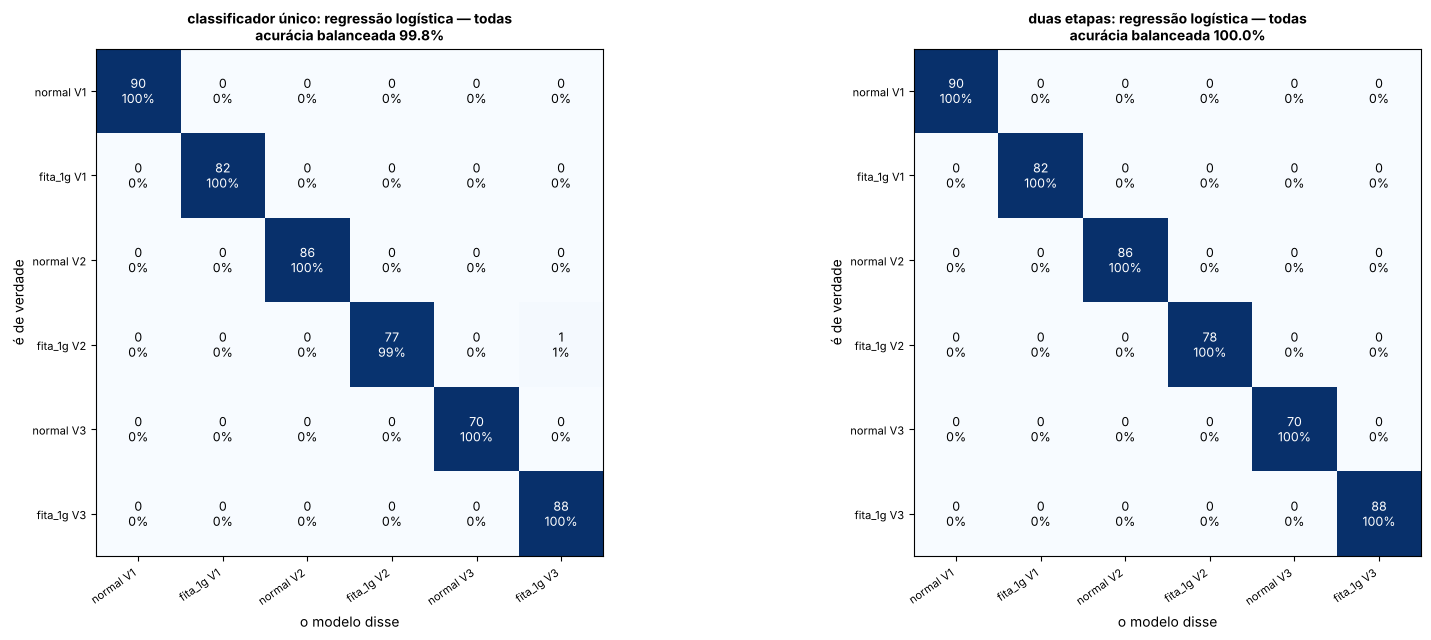

In [31]:
reais_c = dev["rotulo_classe"].to_numpy()
principal_c = tabela_c.loc[[CONJUNTO_PRINCIPAL]]
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, arquitetura in zip(axs, ["classificador único", "duas etapas"]):
    melhor = aplicar_regra_de_escolha(principal_c[principal_c.index.get_level_values("arquitetura") == arquitetura]
                                      .loc[lambda t: ~t.index.get_level_values("modelo").str.startswith("referência")])
    previsto = previsoes_c[(melhor["modelo"], CONJUNTO_PRINCIPAL, arquitetura)]
    plotar_matriz(reais_c, previsto, ORDEM_CLASSES, f"{arquitetura}: {melhor['modelo']} — {CONJUNTO_PRINCIPAL}", ax=ax)
plt.tight_layout()
plt.show()

### Conclusões do Passo 10 (nesta execução)

**As duas arquiteturas chegam a 99,4–100%.** Não há diferença prática entre o classificador único e as duas etapas com estes dados: com rótulos, a etapa 1 acerta a velocidade sempre (Tarefa A), então a etapa 2 nunca recebe a janela errada.

* **As duas etapas empatam ou ganham por pouco:** com regressão logística, 99,8% (único) contra 100% (duas etapas) em tempo, FFT e todas.
* **Os modelos de referência:** chute 12,8% (o acaso com 6 classes é ~17%) e stump ~26%.
* **Por que ainda vale a arquitetura em duas etapas:** com várias falhas e falhas sutis, separar o problema deixa cada detector especializado no normal da sua velocidade, como vimos no Notebook 04. Com uma falha só e forte, a vantagem não aparece. **A comparação precisa ser refeita com a nova coleta.**

## Passo 11 — Testes anti-ilusão

**O que buscamos:** ter certeza de que os acertos vêm da **falha**, e não de um atalho. Todos usam **só o conjunto de desenvolvimento**: o teste trancado continua fechado.

1. **Rótulos embaralhados por bloco (11.1):** trocamos os rótulos entre os blocos ao acaso, de modo que cada bloco recebe a classe de outro, e refazemos a validação. Agora não existe relação real entre sinal e rótulo. **Um modelo honesto cai para perto do acaso** (1/6 ≈ 17% de acurácia balanceada nas 6 classes). Se ele continuar acertando, há vazamento: o modelo está reconhecendo o bloco ou a gravação, e não a classe. Repetimos várias vezes para obter um **p-valor**: a fração de embaralhamentos que chegou ao resultado real.
2. **Divisão cronológica (11.2):** treina no **começo** de cada gravação e testa no **fim**, com guarda entre os dois. Mede se o modelo sobrevive à **deriva** ao longo do tempo (aquecimento, por exemplo).
3. **O stump (11.3):** qual pergunta única o melhor stump escolheu e quanto ele acerta. Diz o quanto o problema é fácil.
4. **Quais features o Random Forest usou (11.4):** se o modelo se apoia em features com sentido físico (vibração, harmônicas da rotação), o resultado é mais confiável.
5. **Erros no tempo (11.5):** onde, ao longo de cada gravação, a validação errou.

### 11.1 — Rótulos embaralhados por bloco

**Como ler:** a primeira linha é o resultado real (validação normal). As outras resumem os embaralhamentos. Se o real estiver muito acima de todos os embaralhados, o p-valor é o menor possível com `N_EMBARALHAMENTOS` repetições: 1 / (N + 1).

In [32]:
def embaralhar_por_bloco(dev, coluna_rotulo, gerador):
    """Troca os rótulos entre os blocos: cada bloco inteiro recebe o rótulo de outro bloco, ao acaso."""
    chave = dev["base"] + "|" + dev["bloco"].astype(str)
    rotulo_por_bloco = dev.groupby(chave)[coluna_rotulo].first()
    novo = pd.Series(gerador.permutation(rotulo_por_bloco.to_numpy()), index=rotulo_por_bloco.index)
    copia = dev.copy()
    copia[coluna_rotulo] = chave.map(novo).to_numpy()
    return copia


def testar_rotulos_embaralhados(dev, colunas, fabrica_modelo, folds, coluna_rotulo="rotulo_classe", n=N_EMBARALHAMENTOS):
    """Acurácia balanceada real e com rótulos embaralhados por bloco; p-valor do teste de permutação."""
    gerador = np.random.default_rng(SEMENTE)
    real = 100 * balanced_accuracy_score(dev[coluna_rotulo], validar(fabrica_modelo, dev, colunas, coluna_rotulo, folds))
    embaralhados = []
    for _ in range(n):
        falso = embaralhar_por_bloco(dev, coluna_rotulo, gerador)
        embaralhados.append(100 * balanced_accuracy_score(falso[coluna_rotulo], validar(fabrica_modelo, falso, colunas, coluna_rotulo, folds)))
    p_valor = (1 + sum(e >= real for e in embaralhados)) / (n + 1)
    return real, np.array(embaralhados), p_valor

In [33]:
linhas = []
for nome_modelo in ["regressão logística", "KNN (k=5)", "Random Forest"]:
    real, embaralhados, p_valor = testar_rotulos_embaralhados(
        dev, COLUNAS_TODAS, lambda: criar_pipeline(MODELOS[nome_modelo](), COLUNAS_TODAS), folds)
    linhas.append({"modelo": nome_modelo, "real (%)": real, "embaralhado: média (%)": embaralhados.mean(),
                   "embaralhado: máximo (%)": embaralhados.max(), "acaso (%)": 100 / len(ORDEM_CLASSES), "p-valor": p_valor})
display(pd.DataFrame(linhas).set_index("modelo").round(3))

,real (%),embaralhado: média (%),embaralhado: máximo (%),acaso (%),p-valor
modelo,,,,,
regressão logística,99.786,14.724,25.886,16.667,0.048
KNN (k=5),100.000,15.316,23.464,16.667,0.048
Random Forest,100.000,14.046,27.487,16.667,0.048


### 11.2 — Divisão cronológica: treinar no começo, testar no fim

**Como funciona:** em cada gravação, as janelas de desenvolvimento dos primeiros `FRACAO_INICIO_CRONOLOGICO` (70%) do tempo são o treino, e as do fim são o teste, com a guarda entre os dois. Se o desempenho cair muito em relação à validação por blocos, o sinal **muda com o tempo** (deriva), e um modelo treinado hoje pode errar amanhã.

In [34]:
def dividir_cronologicamente(dev, fracao=FRACAO_INICIO_CRONOLOGICO):
    """Um único 'fold': treino = começo de cada gravação; teste = fim; guarda entre os dois."""
    posicao = dev.groupby("base")["janela"].rank(pct=True)
    no_teste = posicao > fracao
    guarda = marcar_guarda(dev, no_teste)
    treino = np.where(~no_teste.to_numpy() & ~guarda.to_numpy())[0]
    teste = np.where(no_teste.to_numpy())[0]
    return [(treino, teste, np.where(guarda.to_numpy())[0])]

In [35]:
fold_cronologico = dividir_cronologicamente(dev)
linhas = []
for tarefa, coluna, classes in (("A: velocidade", "rotulo_velocidade", ORDEM_VELOCIDADES),
                                ("B: normal x anomalia", "rotulo_binario", CLASSES_BINARIAS),
                                ("C: 6 classes", "rotulo_classe", ORDEM_CLASSES)):
    for nome_modelo in ORDEM_SIMPLICIDADE:
        previsto = validar(lambda: criar_pipeline(MODELOS[nome_modelo](), COLUNAS_TODAS), dev, COLUNAS_TODAS, coluna, fold_cronologico)
        teste = fold_cronologico[0][1]
        linhas.append({"tarefa": tarefa, "modelo": nome_modelo,
                       "acurácia balanceada no fim da gravação (%)": 100 * balanced_accuracy_score(dev[coluna].to_numpy()[teste], previsto[teste])})
display(pd.DataFrame(linhas).set_index(["tarefa", "modelo"]).round(1))

acurácia balanceada no fim da gravação (%)
tarefa               modelo                                                         
A: velocidade        regressão logística                                       100.0
                     KNN (k=5)                                                 100.0
                     SVM (RBF)                                                 100.0
                     Random Forest                                             100.0
B: normal x anomalia regressão logística                                       100.0
                     KNN (k=5)                                                 100.0
                     SVM (RBF)                                                 100.0
                     Random Forest                                             100.0
C: 6 classes         regressão logística                                       100.0
                     KNN (k=5)                                                 100.0
                     SVM (RBF)                                                 100.0
                     Random Forest                                             100.0

### 11.3 — O stump: qual pergunta única ele escolhe?

**Como ler:** para cada tarefa, a feature e o limite que a árvore de uma pergunta só escolheu (treinada em todo o desenvolvimento) e a acurácia balanceada dela na validação (das tabelas anteriores). Um stump com acerto alto mostra que **uma única feature** já resolve a tarefa.

In [36]:
def descrever_stump(dev, colunas, coluna_rotulo):
    """Treina o stump no desenvolvimento e devolve a pergunta que ele faz (feature e limite, na escala original)."""
    pipeline = criar_pipeline(MODELOS["referência: stump (1 pergunta)"](), colunas).fit(dev[colunas], dev[coluna_rotulo])
    arvore = pipeline.named_steps["modelo"]
    nomes = [c for c in colunas if c not in COLUNAS_SEM_LOG] + [c for c in colunas if c in COLUNAS_SEM_LOG]
    indice = arvore.tree_.feature[0]
    limite_padronizado = arvore.tree_.threshold[0]
    scaler = pipeline.named_steps["scaler"]
    limite_log = limite_padronizado * scaler.scale_[indice] + scaler.mean_[indice]
    feature = nomes[indice]
    limite = np.exp(limite_log) if feature not in COLUNAS_SEM_LOG else limite_log
    return feature, limite

In [37]:
linhas = []
for tarefa, coluna, tabela in (("A: velocidade", "rotulo_velocidade", tabela_a), ("B: normal x anomalia", "rotulo_binario", tabela_b)):
    feature, limite = descrever_stump(dev, COLUNAS_TODAS, coluna)
    linhas.append({"tarefa": tarefa, "pergunta do stump": f"{feature} > {limite:.3g}?",
                   "acurácia balanceada na validação (%)": tabela.loc[("todas", "referência: stump (1 pergunta)"), "acurácia balanceada (%)"]})
display(pd.DataFrame(linhas).set_index("tarefa").round(1))

,pergunta do stump,acurácia balanceada na validação (%)
tarefa,,
A: velocidade,pico_z > 1.31?,60.0
B: normal x anomalia,fft_025_035Hz_y > 0.0344?,95.1


### 11.4 — Quais features o Random Forest usou?

**O que é a importância:** cada árvore do Random Forest faz perguntas sobre as features. A importância de uma feature é o quanto as perguntas sobre ela ajudaram a separar as classes, somado em todas as árvores (total = 1).

**Como ler:** as 15 mais importantes e, no gráfico da direita, a soma por tipo (tempo, FFT, rotação). **Cuidado:** quando várias features carregam a mesma informação (por exemplo, `std_x` e `pico_x`), a importância se divide entre elas. Uma feature com importância baixa não é necessariamente inútil, pode só ter uma "irmã" que levou o crédito.

In [38]:
def importancias_random_forest(dev, colunas, coluna_rotulo):
    """Importância de cada feature num Random Forest treinado em todo o desenvolvimento."""
    pipeline = criar_pipeline(MODELOS["Random Forest"](), colunas).fit(dev[colunas], dev[coluna_rotulo])
    nomes = [c for c in colunas if c not in COLUNAS_SEM_LOG] + [c for c in colunas if c in COLUNAS_SEM_LOG]
    return pd.Series(pipeline.named_steps["modelo"].feature_importances_, index=nomes).sort_values(ascending=False)


def tipo_da_feature(nome):
    if nome.startswith(("std_", "kurt_", "pico_")):
        return "tempo"
    return "FFT" if nome.startswith("fft_") else "rotação"

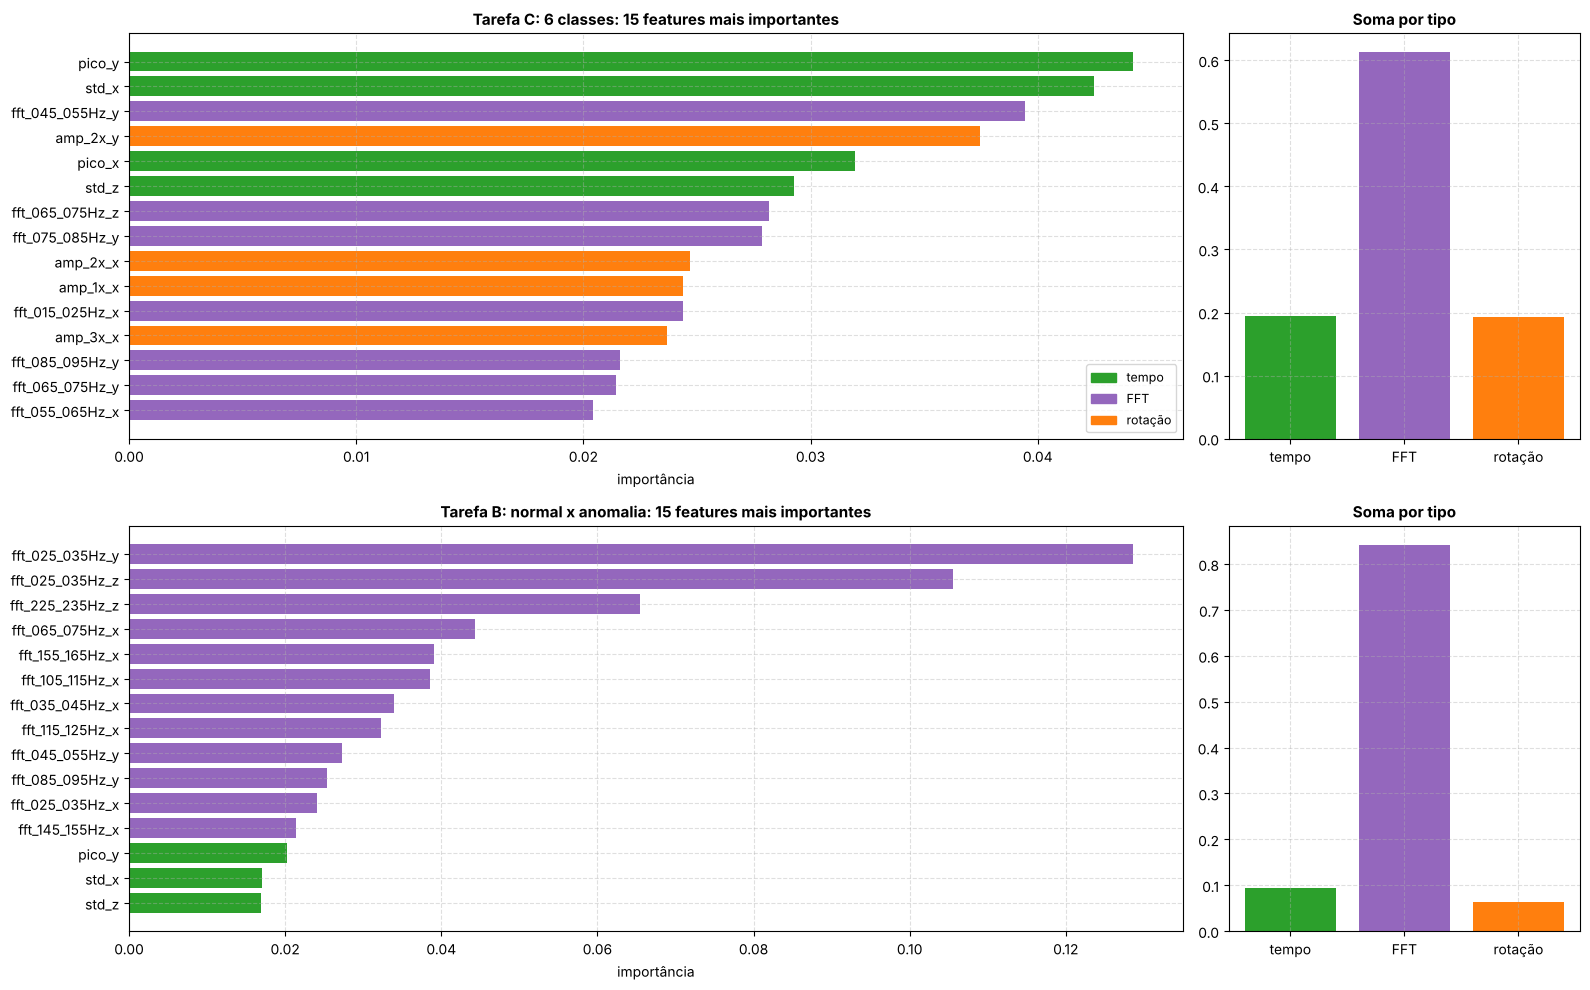

In [39]:
fig, axs = plt.subplots(2, 2, figsize=(16, 10), gridspec_kw={"width_ratios": [3, 1]})
for linha, (tarefa, coluna) in enumerate((("C: 6 classes", "rotulo_classe"), ("B: normal x anomalia", "rotulo_binario"))):
    importancias = importancias_random_forest(dev, COLUNAS_TODAS, coluna)
    top = importancias.head(15)[::-1]
    axs[linha, 0].barh(top.index, top.values, color=[CORES_TIPO[tipo_da_feature(n)] for n in top.index])
    axs[linha, 0].set_title(f"Tarefa {tarefa}: 15 features mais importantes", fontsize=11, fontweight="bold")
    axs[linha, 0].set_xlabel("importância")
    por_tipo = importancias.groupby(importancias.index.map(tipo_da_feature)).sum().reindex(list(CORES_TIPO))
    axs[linha, 1].bar(por_tipo.index, por_tipo.values, color=[CORES_TIPO[t] for t in por_tipo.index])
    axs[linha, 1].set_title("Soma por tipo", fontsize=11, fontweight="bold")
axs[0, 0].legend(handles=[Patch(color=c, label=t) for t, c in CORES_TIPO.items()], fontsize=9)
plt.tight_layout()
plt.show()

### 11.5 — Erros no tempo (validação cruzada da Tarefa C)

**Como ler:** cada faixa é uma gravação, com as janelas de desenvolvimento em ordem de tempo. **Verde = acerto, X vermelho = erro** do melhor modelo da Tarefa C na validação cruzada. O que procurar: erros juntos no começo ou no fim (manuseio, aquecimento), alternados (ciclo da oscilação) ou espalhados (ruído).

In [40]:
def plotar_erros_no_tempo(dev, previsto, titulo):
    """Acerto (verde) ou erro (X vermelho) de cada janela, por gravação, em ordem de tempo."""
    bases_ordenadas = sorted(dev["base"].unique(), key=lambda b: (b.split("_vel_")[1], b))
    fig, axs = plt.subplots(len(bases_ordenadas), 1, figsize=(14, 0.9 * len(bases_ordenadas) + 1.2), sharex=True, squeeze=False)
    for ax, base in zip(axs[:, 0], bases_ordenadas):
        sel = (dev["base"] == base).to_numpy()
        janelas = dev["janela"].to_numpy()[sel]
        acerto = previsto[sel] == dev["rotulo_classe"].to_numpy()[sel]
        ax.scatter(janelas[acerto], np.zeros(acerto.sum()), s=10, color="tab:green")
        ax.scatter(janelas[~acerto], np.zeros((~acerto).sum()), s=30, color="tab:red", marker="x")
        ax.set_yticks([])
        ax.set_title(f"{base}: {(~acerto).sum()} erros em {len(acerto)} janelas", fontsize=9, fontweight="bold", loc="left")
    axs[-1, 0].set_xlabel(f"janela (cada uma = {JANELA_S} s)")
    fig.suptitle(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

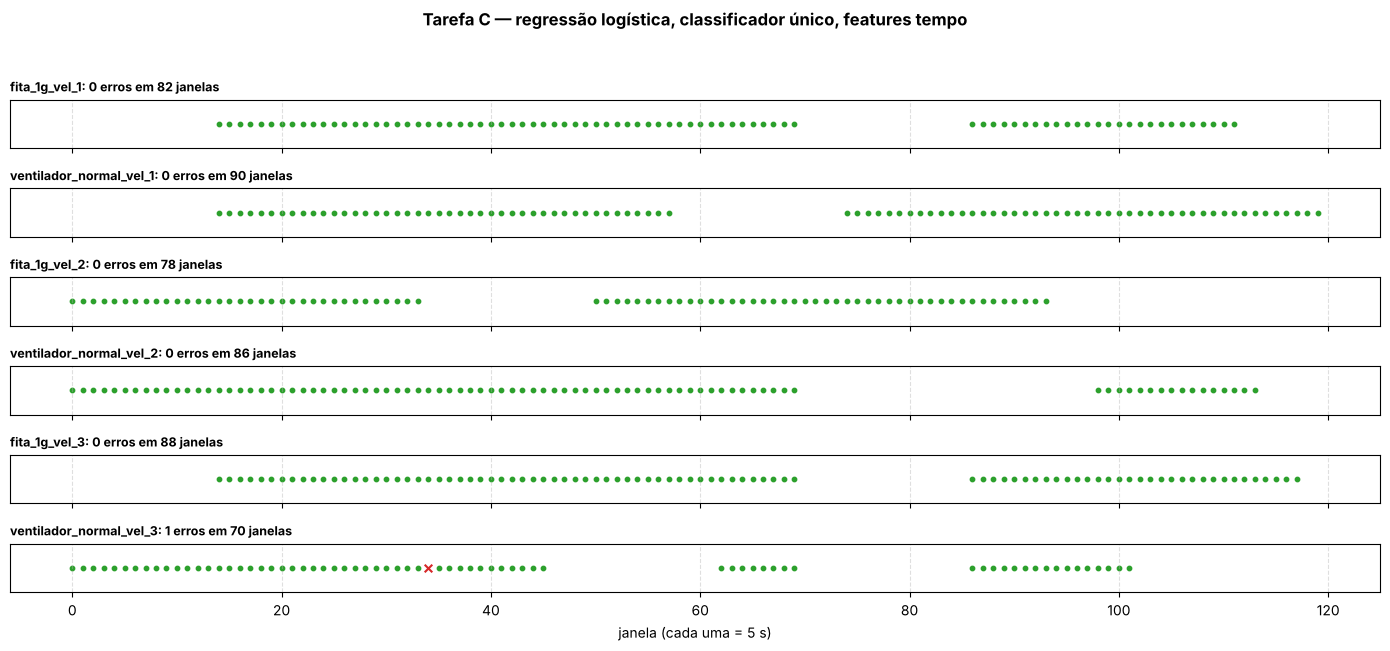

In [41]:
escolha_c_previa = aplicar_regra_de_escolha(tabela_c[~tabela_c.index.get_level_values("modelo").str.startswith("referência")])
plotar_erros_no_tempo(dev, previsoes_c[(escolha_c_previa["modelo"], escolha_c_previa["features"], escolha_c_previa["arquitetura"])],
                      f"Tarefa C — {escolha_c_previa['modelo']}, {escolha_c_previa['arquitetura']}, features {escolha_c_previa['features']}")

### Conclusões do Passo 11 (nesta execução)

**11.1 — Rótulos embaralhados:** com os rótulos trocados entre blocos, os três modelos caem para **14–15%** de acurácia balanceada, abaixo do acaso (16,7%), e o melhor embaralhamento não passa de 27%. O resultado real (99,8–100%) foi maior que **todos** os 20 embaralhamentos: p-valor = 0,048, o menor possível com 20 repetições (1/21). **Não há sinal de vazamento**: o modelo não está reconhecendo blocos ou gravações, e sim as classes.

**11.2 — Divisão cronológica:** treinando nos primeiros 70% e testando no fim de cada gravação, **100% nas três tarefas e nos quatro modelos**. Com esta fita, a deriva ao longo da gravação (inclusive a da Vel 1) **não atrapalha** a classificação.

**11.3 — Stump:**
* **Velocidade:** "`pico_z` > 1,31?" acerta só 60%. Uma pergunta não separa três velocidades.
* **Normal × anomalia:** "FFT de 25–35 Hz no eixo y > 0,034?" acerta **95,1%**. Uma única faixa do espectro quase resolve a detecção. A faixa contém harmônicas da rotação (por exemplo, o 2X da Vel 1, que fica entre ~22 e 28 Hz). A interpretação física ainda precisa ser confirmada (vale levar ao orientador).

**11.4 — Features do Random Forest:**
* **6 classes:** usa uma mistura: `pico_y`, `std_x`, FFT de 45–55 Hz no eixo y e a **amplitude em 2X** (`amp_2x_y`) entre as mais importantes. Faz sentido: velocidade aparece na rotação e no espectro, falha na intensidade e nas harmônicas.
* **Normal × anomalia:** domina a **FFT de 25–35 Hz nos eixos y e z** (as mesmas do stump), seguida de faixas mais altas (225–235 Hz no z, 65–75 Hz no x).
* **Cuidado ao ler a soma por tipo:** a FFT tem 90 das 109 features, então naturalmente soma mais importância. O que vale é o ranking das primeiras.

**11.5 — Erros no tempo:** a validação errou só **uma janela** no melhor modelo da Tarefa C, então não há padrão (início, fim ou alternância) a analisar com estes dados.

## Passo 12 — Regra de escolha e abertura do teste trancado

**A regra, decidida antes de abrir o trancado:**

1. Para cada tarefa, fica o modelo (e o conjunto de features, e para a Tarefa C a arquitetura) com a **maior acurácia balanceada na validação cruzada**.
2. Se dois ficarem a menos de `EMPATE_PP` pontos percentuais um do outro, fica **o mais simples**, na ordem: regressão logística < KNN < SVM < Random Forest; classificador único < duas etapas; menos features < mais features.
3. **Os modelos de referência não podem ser escolhidos.**

**A abertura:** cada modelo escolhido é treinado de novo com **todo o conjunto de desenvolvimento** e avaliado **uma vez** no teste trancado.

**Como ler:** se o trancado ficar perto da validação cruzada, a estimativa era confiável. Se ficar bem abaixo, a validação estava otimista (ou as escolhas "decoraram" a validação), e o número que vale para o TCC é **o do trancado**.

> **Não volte para mudar escolhas depois de ver o trancado.** Se precisar mudar, o trancado atual vira "usado", e um novo teste só é honesto com dados que ainda não foram vistos: a nova coleta.

In [42]:
def escolher_modelos(tabela_a, tabela_b, tabela_c):
    """Aplica a regra do Passo 12 às três tarefas (sem os modelos de referência)."""
    reais = lambda t: t[~t.index.get_level_values("modelo").str.startswith("referência")]
    return {"A: velocidade": aplicar_regra_de_escolha(reais(tabela_a)),
            "B: normal x anomalia": aplicar_regra_de_escolha(reais(tabela_b)),
            "C: 6 classes": aplicar_regra_de_escolha(reais(tabela_c))}

In [43]:
escolhas = escolher_modelos(tabela_a, tabela_b, tabela_c)
tabela_escolhas = pd.DataFrame({tarefa: {"modelo": e["modelo"], "features": e["features"],
                                         "arquitetura": e.get("arquitetura", "—"),
                                         "acurácia balanceada na validação (%)": round(e["acurácia balanceada (%)"], 2)}
                                for tarefa, e in escolhas.items()}).T
display(tabela_escolhas)

,modelo,features,arquitetura,acurácia balanceada na validação (%)
A: velocidade,regressão logística,só f1x_hz,—,100.0
B: normal x anomalia,regressão logística,rotação,—,99.6
C: 6 classes,regressão logística,tempo,classificador único,99.76


### 12.1 — Abrindo o teste trancado (uma vez só)

**O que o código faz:** treina cada modelo escolhido com **todo o conjunto de desenvolvimento** (com o scaler ajustado nele) e prevê as janelas do teste trancado, que nenhum passo anterior usou.

In [44]:
def avaliar_no_trancado(escolha, coluna_rotulo, classes):
    """Treina o modelo escolhido em todo o desenvolvimento e avalia no teste trancado."""
    colunas = CONJUNTOS_TODOS[escolha["features"]]
    fabrica = MODELOS[escolha["modelo"]]
    if escolha.get("arquitetura") == "duas etapas":
        modelo = DuasEtapas(criar_pipeline(fabrica(), colunas), criar_pipeline(fabrica(), colunas))
    else:
        modelo = criar_pipeline(fabrica(), colunas)
    modelo.fit(dev[colunas], dev[coluna_rotulo])
    previsto = modelo.predict(trancado[colunas])
    return previsto, metricas(trancado[coluna_rotulo], previsto, classes)

,modelo,features,arquitetura,validação cruzada: acurácia balanceada (%),teste trancado: acurácia balanceada (%),janelas no trancado
tarefa,,,,,,
A: velocidade,regressão logística,só f1x_hz,—,100.00,100.00,146
B: normal x anomalia,regressão logística,rotação,—,99.60,98.65,146
C: 6 classes,regressão logística,tempo,classificador único,99.76,99.36,146


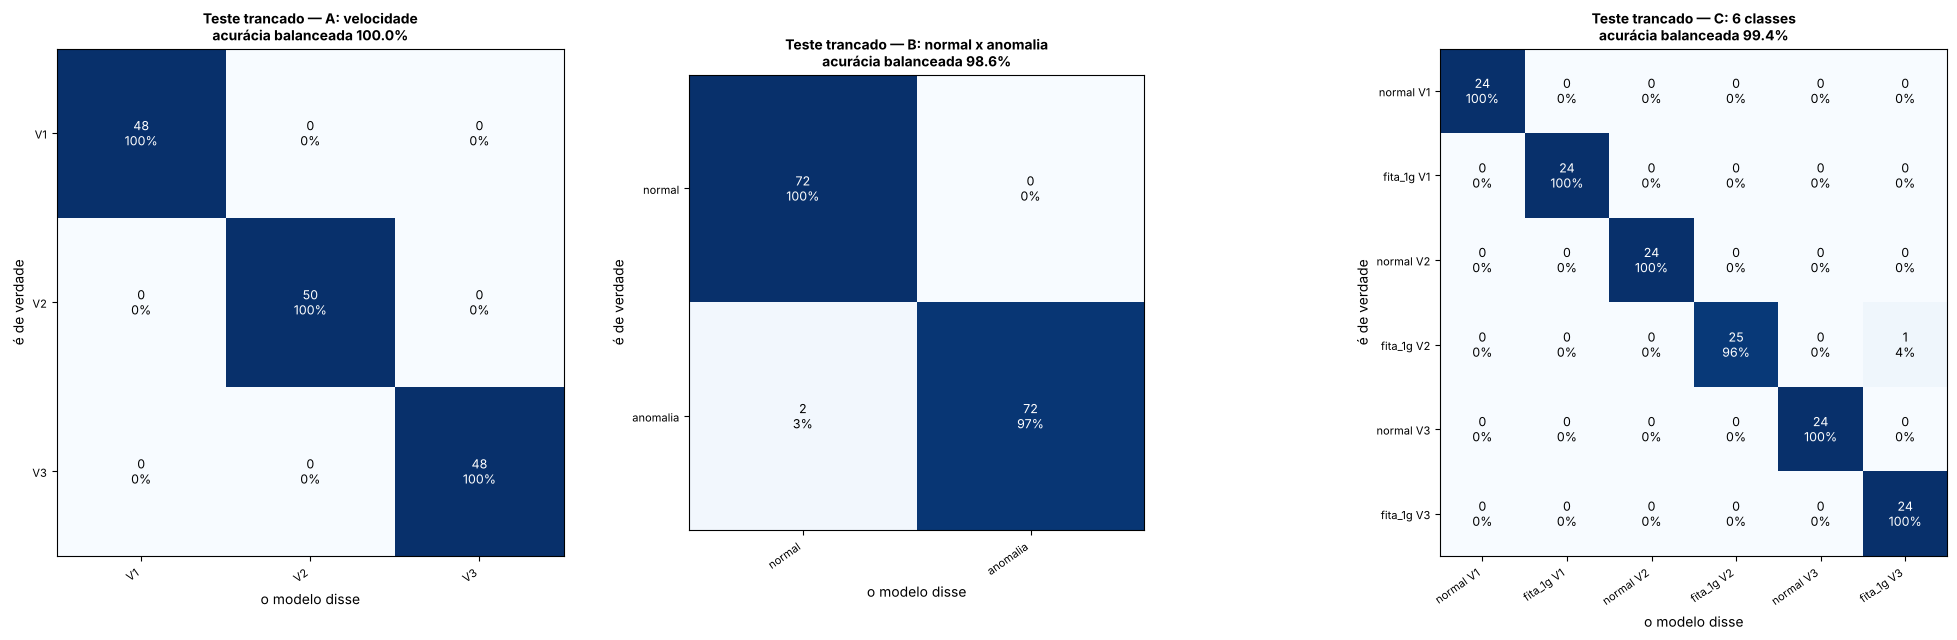

Detecção no trancado (tarefa B), por velocidade:


,recall anomalia (%),falso alarme (%)
velocidade,,
V1,91.7,0.0
V2,100.0,0.0
V3,100.0,0.0


Erros no trancado — A: velocidade: nenhum
Erros no trancado — B: normal x anomalia: fita_1g_vel_1 janela 3, fita_1g_vel_1 janela 10
Erros no trancado — C: 6 classes: fita_1g_vel_2 janela 109


In [45]:
TAREFAS = {"A: velocidade": ("rotulo_velocidade", ORDEM_VELOCIDADES),
           "B: normal x anomalia": ("rotulo_binario", CLASSES_BINARIAS),
           "C: 6 classes": ("rotulo_classe", ORDEM_CLASSES)}
resultados_trancado, linhas = {}, []
for tarefa, (coluna, classes) in TAREFAS.items():
    previsto, m = avaliar_no_trancado(escolhas[tarefa], coluna, classes)
    resultados_trancado[tarefa] = previsto
    linhas.append({"tarefa": tarefa, "modelo": escolhas[tarefa]["modelo"], "features": escolhas[tarefa]["features"],
                   "arquitetura": escolhas[tarefa].get("arquitetura", "—"),
                   "validação cruzada: acurácia balanceada (%)": escolhas[tarefa]["acurácia balanceada (%)"],
                   "teste trancado: acurácia balanceada (%)": m["acurácia balanceada (%)"],
                   "janelas no trancado": len(trancado)})
display(pd.DataFrame(linhas).set_index("tarefa").round(2))

fig, axs = plt.subplots(1, 3, figsize=(22, 6.5), gridspec_kw={"width_ratios": [1, 0.8, 1.6]})
for ax, (tarefa, (coluna, classes)) in zip(axs, TAREFAS.items()):
    plotar_matriz(trancado[coluna].to_numpy(), resultados_trancado[tarefa], classes, f"Teste trancado — {tarefa}", ax=ax)
plt.tight_layout()
plt.show()
print("Detecção no trancado (tarefa B), por velocidade:")
display(recall_por_velocidade(trancado, resultados_trancado["B: normal x anomalia"]).round(1))

for tarefa, (coluna, _) in TAREFAS.items():
    errados = trancado[resultados_trancado[tarefa] != trancado[coluna].to_numpy()]
    lista = ", ".join(f"{b} janela {j}" for b, j in zip(errados["base"], errados["janela"])) or "nenhum"
    print(f"Erros no trancado — {tarefa}: {lista}")

### Resultado do teste trancado (nesta execução)

**As escolhas da regra** (maior acurácia balanceada; empate de até 0,5 ponto → o mais simples) foram, nas três tarefas, a **regressão logística**, o modelo mais simples, com o menor conjunto de features que empatou:

| Tarefa | Modelo escolhido | Validação cruzada | **Teste trancado** | Erros no trancado |
| --- | --- | --- | --- | --- |
| A: velocidade | logística, só `f1x_hz` | 100% | **100%** | nenhum |
| B: normal × anomalia | logística, rotação (10 features) | 99,6% | **98,7%** | fita V1, janelas 3 e 10 |
| C: 6 classes | logística, tempo (9 features), classificador único | 99,8% | **99,4%** | fita V2, janela 109 |

**O que isso diz:**

* **O trancado confirmou a validação cruzada:** diferença de no máximo 0,9 ponto. As estimativas da validação eram confiáveis.
* **Tarefa B, Vel 1: recall de 91,7% no trancado** (2 de 24 janelas da fita V1 passaram como normais), com falso alarme de 0% em todas as velocidades. As duas janelas (3 e 10) estão no **primeiro bloco da gravação**, perto do início.
* **Tarefa C: o único erro é a janela 109 da fita V2,** a última janela da gravação, a mesma janela atípica que os Notebooks 03 e 04 já tinham apontado (extrema em 33 features). O modelo a confundiu com fita V3.
* **Lição sobre a regra de empate:** na Tarefa B, a regra preferiu as 10 features de rotação (99,6%) às 109 (100%) por serem "mais simples". No trancado, o modelo com todas as features não teria errado nenhuma janela. **Não mudamos a escolha depois de ver o trancado**, mas para a próxima coleta vale decidir **antes** se a simplicidade deve vir pelo modelo (logística primeiro) ou pelo número de features, e se 0,5 ponto é um empate razoável.

## Resumo e decisões

**O que buscamos:** levar para o Notebook 05b e para o modelo final o que este notebook mostrou.

### Decisões e o que levar adiante

**Respostas do notebook:**

1. **Velocidade:** 100% com rótulos, até com uma feature só (`f1x_hz`). O erro do K-Means (fita V3 na Vel 2) some com rótulos.
2. **Normal × anomalia:** 98,7% no trancado (validação 99,6%), com 0% de falso alarme; a Vel 1 é a mais difícil (91,7% no trancado).
3. **6 classes:** 99,4% no trancado; classificador único e duas etapas empatam com estes dados.

**Decisões de método (valem para os dados novos):**

| Decisão | Por quê |
| --- | --- |
| **Blocos de 60 s, guarda de 10 s, 2 blocos trancados por gravação** | Guarda cobre a vizinhança imediata; o bloco cobre ~5 ciclos da oscilação; a semelhança de longo alcance é periódica (a máquina repetindo o padrão), não vazamento |
| **Pipeline log → scaler → modelo**, ajustado só no treino | Elimina o vazamento do scaler que o Notebook 04 tinha |
| **Acurácia balanceada** como critério; recall por velocidade e falso alarme sempre ao lado | Uma velocidade mal detectada não fica escondida na média |
| **Etapa de velocidade com `f1x_hz`** como candidata | 100% com uma feature que depende da velocidade e quase não da falha |
| **Rever a regra de empate antes da nova coleta** | Na Tarefa B ela preferiu menos features e perdeu 2 janelas no trancado |

**Ressalvas para o texto do TCC:**

* **Uma falha só, forte:** uma única faixa de FFT detecta 95% dela. Os números altos mostram que **o método funciona**, não que falhas sutis serão detectadas.
* **Treino e teste vêm da mesma gravação**, em trechos diferentes: medimos generalização **dentro da sessão**. Para outra sessão, só a nova coleta.
* **O teste trancado atual já foi aberto.** Qualquer mudança de método daqui em diante precisa ser avaliada em dados novos.

**Próximo passo:** Notebook 05b, o detector treinado **só com o ventilador saudável**, com os mesmos blocos e o mesmo teste trancado.

## O que conferir antes de seguir para o Notebook 05b

* [ ] **Passos 3 e 4:** você entendeu por que blocos, por que guarda e de onde sai o teste trancado.
* [ ] **Passo 5:** você entendeu por que o trancado não aparece em nenhuma rodada da validação.
* [ ] **Passo 6:** o scaler é ajustado só no treino (pipeline).
* [ ] **Passos 8 a 10:** os melhores modelos e as comparações (features, arquiteturas) estão anotados.
* [ ] **Passo 11:** os testes anti-ilusão não acusaram vazamento.
* [ ] **Passo 12:** o número do teste trancado está anotado **e nada foi mudado depois de vê-lo**.

**Próximo passo:** Notebook 05b, **detector treinado só com o ventilador saudável**, usando a mesma divisão em blocos e o mesmo teste trancado.